# Visualization of Platemaps

__Author: Runxi Shen__

__Date: 2025-06-29__

This is a notebook that helps draw up the distribution of alleles and their types on a 384-well platemap to help me better understand the experimental set-ups of different batches and how we need to adjust our analyses pipeline to accommodate the changes accordingly.

In [32]:
import polars as pl
import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import sys
%matplotlib inline
sys.path.append("../../..")
from utils import *

## Disable truncation globally
pl.Config.set_tbl_rows(20)  # Show all rows
pl.Config.set_tbl_cols(40)  # Show all columns

## define control types
TC = ["EGFP"]
NC = ["RHEB", "MAPK9", "PRKACB", "SLIRP"]
PC = ["ALK", "ALK_Arg1275Gln", "PTK2B"]
cNC = ["Renilla"]
cPC = ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
       "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# CTRLS = TC + NC + PC

## Metadata

In [33]:
meta_dat_df = pd.read_csv("../../inputs/corrected_metadata/2025_05_batch17/B17_Pilot.csv")
meta_dat_df

,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,...,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,gene,allele,final_gene_allele
0,SEMA4A,SEMA4A_,Lacoste_Bth2_WTs,NaN,NaN,664_Lacoste_P01_Test_T1,A01,1,A01,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SEMA4A,SEMA4A_Gly35Arg,colPCR_attL_LacosteBth2_01,B01,2.0,664_Lacoste_P01_Test_T1,B01,2,C01,B17A9R1,...,103G>A,Gly35Arg,CCSBVarC015698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SEMA4A,SEMA4A_His138Arg,colPCR_attL_LacosteBth2_01,C01,3.0,664_Lacoste_P01_Test_T1,C01,3,E01,B17A9R1,...,413A>G,His138Arg,CCSBVarC015811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SEMA4A,SEMA4A_Asp167Val,colPCR_attL_LacosteBth2_01,D01,4.0,664_Lacoste_P01_Test_T1,D01,4,G01,B17A9R1,...,500A>T,Asp167Val,CCSBVarC015813,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,SEMA4A,SEMA4A_His306Gln,colPCR_attL_LacosteBth2_01,E01,5.0,664_Lacoste_P01_Test_T1,E01,5,I01,B17A9R1,...,918C>A,His306Gln,CCSBVarC015818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363,MCOLN1,MCOLN1_Ala26Val,colPCR_attL_LacosteBth2_01,A12,89.0,664_Lacoste_P01_Test_T4,H11,88,P22,B17A9R1,...,77C>T,Ala26Val,CCSBVarC016319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,MCOLN1,MCOLN1_Glu123Lys,colPCR_attL_LacosteBth2_01,C12,91.0,664_Lacoste_P01_Test_T4,A12,89,B24,B17A9R1,...,367G>A,Glu123Lys,CCSBVarC016262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,MCOLN1,MCOLN1_Gly154Cys,colPCR_attL_LacosteBth2_01,D12,92.0,664_Lacoste_P01_Test_T4,B12,90,D24,B17A9R1,...,460G>T,Gly154Cys,CCSBVarC016275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,MCOLN1,MCOLN1_His286Asn,colPCR_attL_LacosteBth2_01,E12,93.0,664_Lacoste_P01_Test_T4,C12,91,F24,B17A9R1,...,856C>A,His286Asn,CCSBVarC016364,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
meta_dat_df[meta_dat_df["node_type"]=="PC"]

,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,...,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,gene,allele,final_gene_allele
27,ALK,ALK_,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T1,D04,28,G07,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,ALK,ALK_Arg1275Gln,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T1,E05,37,I09,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
119,ALK,ALK_,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T2,D04,28,G08,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
128,ALK,ALK_Arg1275Gln,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T2,E05,37,I10,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,ALK,ALK_,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T3,D04,28,H07,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
220,ALK,ALK_Arg1275Gln,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T3,E05,37,J09,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
303,ALK,ALK_,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T4,D04,28,H08,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
312,ALK,ALK_Arg1275Gln,664 Controls,NaN,NaN,664_Lacoste_P01_Test_T4,E05,37,J10,B17A9R1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
meta_dat_df["gene_allele"] = meta_dat_df["gene_allele"].apply(lambda x: x[:-1] if type(x)==str and x.endswith("_") else x)
meta_dat_df["gene_symbol"] = meta_dat_df["gene_allele"].apply(lambda x: x.split("_")[0] if type(x)==str else x)
# all(meta_dat_df["gene_symbol"]==meta_dat_df["symbol"])
meta_dat_df[meta_dat_df["gene_symbol"]!=meta_dat_df["symbol"]]

meta_dat_df["symbol"] = meta_dat_df["gene_allele"].apply(lambda x: x.split("_")[0] if type(x)==str else x)
meta_dat_df["plate_map_name"] = meta_dat_df["imaging_plate_R1"] + "_P1"
meta_dat_df[meta_dat_df["gene_symbol"]!=meta_dat_df["symbol"]]
meta_dat_df = meta_dat_df[["plate_map_name"]+[col for col in meta_dat_df.columns if col!="plate_map_name"]]
meta_dat_df.insert(1, "well_position", meta_dat_df["imaging_well"])
meta_dat_df_p1 = meta_dat_df.copy().reset_index().drop("index", axis=1)
meta_dat_df_p1

,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,...,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,gene,allele,final_gene_allele,gene_symbol
0,B17A9R1_P1,A01,SEMA4A,SEMA4A,Lacoste_Bth2_WTs,NaN,NaN,664_Lacoste_P01_Test_T1,A01,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SEMA4A
1,B17A9R1_P1,C01,SEMA4A,SEMA4A_Gly35Arg,colPCR_attL_LacosteBth2_01,B01,2.0,664_Lacoste_P01_Test_T1,B01,2,...,Gly35Arg,CCSBVarC015698,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SEMA4A
2,B17A9R1_P1,E01,SEMA4A,SEMA4A_His138Arg,colPCR_attL_LacosteBth2_01,C01,3.0,664_Lacoste_P01_Test_T1,C01,3,...,His138Arg,CCSBVarC015811,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SEMA4A
3,B17A9R1_P1,G01,SEMA4A,SEMA4A_Asp167Val,colPCR_attL_LacosteBth2_01,D01,4.0,664_Lacoste_P01_Test_T1,D01,4,...,Asp167Val,CCSBVarC015813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SEMA4A
4,B17A9R1_P1,I01,SEMA4A,SEMA4A_His306Gln,colPCR_attL_LacosteBth2_01,E01,5.0,664_Lacoste_P01_Test_T1,E01,5,...,His306Gln,CCSBVarC015818,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SEMA4A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363,B17A9R1_P1,P22,MCOLN1,MCOLN1_Ala26Val,colPCR_attL_LacosteBth2_01,A12,89.0,664_Lacoste_P01_Test_T4,H11,88,...,Ala26Val,CCSBVarC016319,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MCOLN1
364,B17A9R1_P1,B24,MCOLN1,MCOLN1_Glu123Lys,colPCR_attL_LacosteBth2_01,C12,91.0,664_Lacoste_P01_Test_T4,A12,89,...,Glu123Lys,CCSBVarC016262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MCOLN1
365,B17A9R1_P1,D24,MCOLN1,MCOLN1_Gly154Cys,colPCR_attL_LacosteBth2_01,D12,92.0,664_Lacoste_P01_Test_T4,B12,90,...,Gly154Cys,CCSBVarC016275,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MCOLN1
366,B17A9R1_P1,F24,MCOLN1,MCOLN1_His286Asn,colPCR_attL_LacosteBth2_01,E12,93.0,664_Lacoste_P01_Test_T4,C12,91,...,His286Asn,CCSBVarC016364,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MCOLN1


In [36]:
# meta_dat_df_p1[meta_dat_df_p1["node_type"]=="TC"]
# meta_dat_df_p1[meta_dat_df_p1["node_type"]=="PC"]

In [37]:
meta_dat_df_p1 = meta_dat_df_p1.drop(["gene","allele","final_gene_allele","gene_symbol"], axis=1)

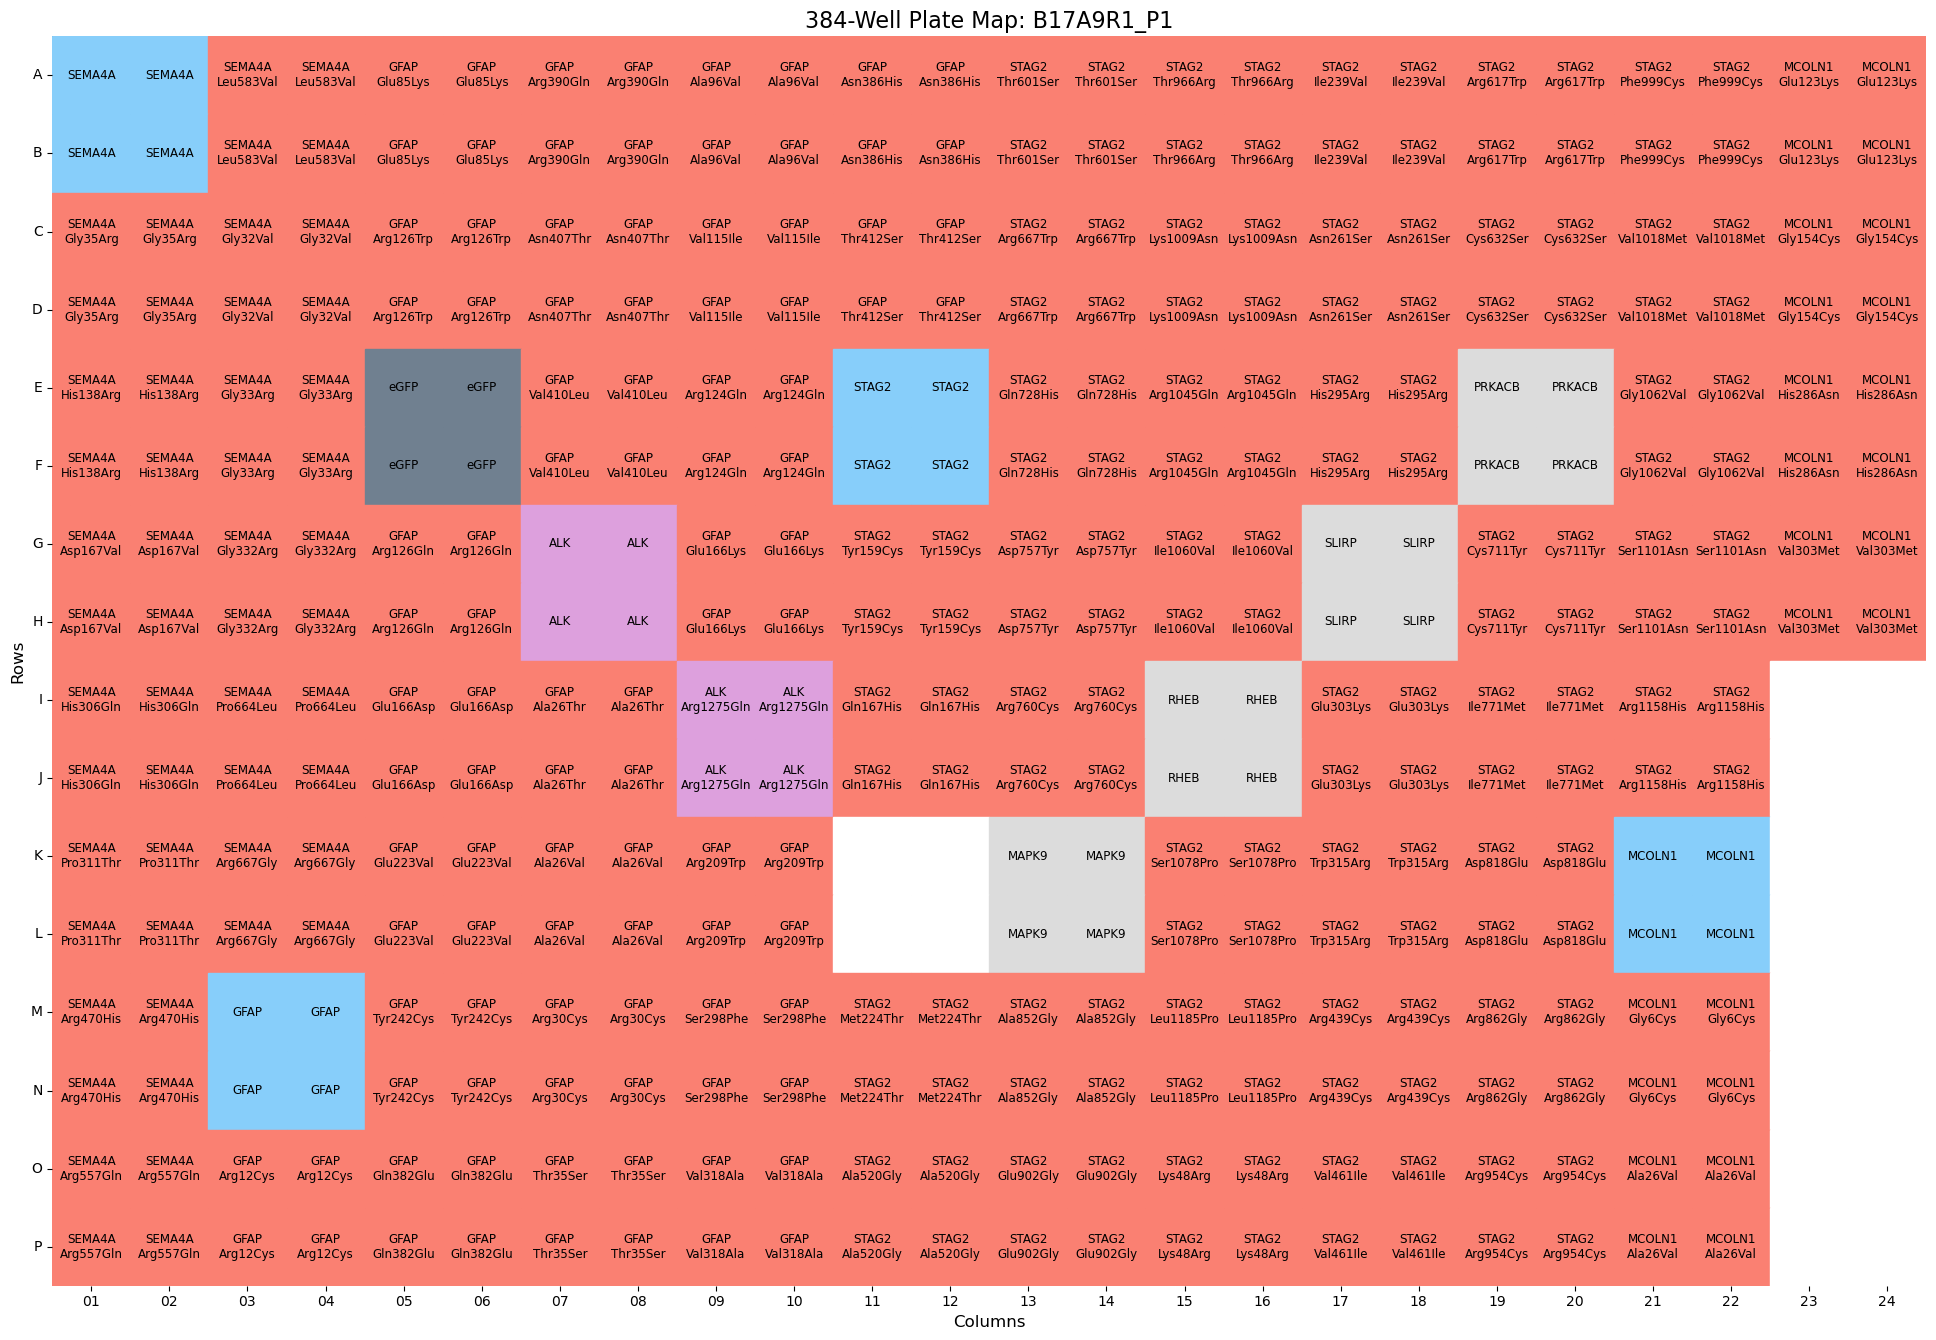

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence,label
u32,str,str,str,str,str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,str,f64,f64,f64,f64,str
0,"""01""","""""","""A""","""01""","""B17A9R1_P1""","""A01""","""SEMA4A""","""SEMA4A""","""Lacoste_Bth2_WTs""",null,null,"""664_Lacoste_P01_Test_T1""","""A01""",1,"""A01""","""B17A9R1""","""B17A9R2""","""disease_wt""",490.0,null,null,null,null,null,null,null,"""SEMA4A"""
1,"""01""","""""","""B""","""01""","""B17A9R1_P1""","""B01""","""SEMA4A""","""SEMA4A""","""Lacoste_Bth2_WTs""",null,null,"""664_Lacoste_P01_Test_T3""","""A01""",1,"""B01""","""B17A9R1""","""B17A9R2""","""disease_wt""",490.0,null,null,null,null,null,null,null,"""SEMA4A"""
2,"""01""","""""","""C""","""01""","""B17A9R1_P1""","""C01""","""SEMA4A""","""SEMA4A_Gly35Arg""","""colPCR_attL_LacosteBth2_01""","""B01""",2.0,"""664_Lacoste_P01_Test_T1""","""B01""",2,"""C01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""103G>A""","""Gly35Arg""","""CCSBVarC015698""",null,null,null,null,"""SEMA4A Gly35Arg"""
3,"""01""","""""","""D""","""01""","""B17A9R1_P1""","""D01""","""SEMA4A""","""SEMA4A_Gly35Arg""","""colPCR_attL_LacosteBth2_01""","""B01""",2.0,"""664_Lacoste_P01_Test_T3""","""B01""",2,"""D01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""103G>A""","""Gly35Arg""","""CCSBVarC015698""",null,null,null,null,"""SEMA4A Gly35Arg"""
4,"""01""","""""","""E""","""01""","""B17A9R1_P1""","""E01""","""SEMA4A""","""SEMA4A_His138Arg""","""colPCR_attL_LacosteBth2_01""","""C01""",3.0,"""664_Lacoste_P01_Test_T1""","""C01""",3,"""E01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""413A>G""","""His138Arg""","""CCSBVarC015811""",null,null,null,null,"""SEMA4A His138Arg"""
5,"""01""","""""","""F""","""01""","""B17A9R1_P1""","""F01""","""SEMA4A""","""SEMA4A_His138Arg""","""colPCR_attL_LacosteBth2_01""","""C01""",3.0,"""664_Lacoste_P01_Test_T3""","""C01""",3,"""F01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""413A>G""","""His138Arg""","""CCSBVarC015811""",null,null,null,null,"""SEMA4A His138Arg"""
6,"""01""","""""","""G""","""01""","""B17A9R1_P1""","""G01""","""SEMA4A""","""SEMA4A_Asp167Val""","""colPCR_attL_LacosteBth2_01""","""D01""",4.0,"""664_Lacoste_P01_Test_T1""","""D01""",4,"""G01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""500A>T""","""Asp167Val""","""CCSBVarC015813""",null,null,null,null,"""SEMA4A Asp167Val"""
7,"""01""","""""","""H""","""01""","""B17A9R1_P1""","""H01""","""SEMA4A""","""SEMA4A_Asp167Val""","""colPCR_attL_LacosteBth2_01""","""D01""",4.0,"""664_Lacoste_P01_Test_T3""","""D01""",4,"""H01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""500A>T""","""Asp167Val""","""CCSBVarC015813""",null,null,null,null,"""SEMA4A Asp167Val"""
8,"""01""","""""","""I""","""01""","""B17A9R1_P1""","""I01""","""SEMA4A""","""SEMA4A_His306Gln""","""colPCR_attL_LacosteBth2_01""","""E01""",5.0,"""664_Lacoste_P01_Test_T1""","""E01""",5,"""I01""","""B17A9R1""","""B17A9R2""","""allele""",490.0,"""918C>A""","""His306Gln""","""CCSBVarC015818""",null,null,null,null,"""SEMA4A His306Gln"""


In [38]:
plot_platemap(pl.DataFrame(meta_dat_df_p1), plate_name="B17A9R1_P1", well_pos_col="imaging_well")

In [40]:
meta_dat_df_p1.to_csv("../../inputs/platemaps/2025_05_23_Batch_17/platemap/B17A9R1_P1.txt", sep="\t", index=False)

In [41]:
# meta_dat_df_p1["imaging_plate_R2"]

## Metadata QC

In [34]:
# meta_dat_df = pd.read_csv("../../inputs/corrected_metadata/2025_03_batch15-16/B15B16_Metadata_seq_update_050625.csv")
# mask = meta_dat_df['final_gene_allele'].notna() & (meta_dat_df['final_gene_allele'] != meta_dat_df['gene_allele'])
# # meta_dat_df.loc[mask,:]
# meta_dat_df.loc[mask, 'gene_allele'] = meta_dat_df.loc[mask, 'final_gene_allele']
# meta_dat_df.loc[mask,:]

# # meta_dat_df[meta_dat_df["symbol"]=="TPM1"]

In [4]:
meta_dat_df["gene_allele"] = meta_dat_df["gene_allele"].apply(lambda x: x[:-1] if type(x)==str and x.endswith("_") else x)
meta_dat_df["gene_symbol"] = meta_dat_df["gene_allele"].apply(lambda x: x.split("_")[0] if type(x)==str else x)
meta_dat_df["symbol"] = meta_dat_df["gene_symbol"]

## mask_null_node
# meta_dat_df["node_type"].unique()
mask_null_node = meta_dat_df["gene_allele"].isna() | meta_dat_df["gene_allele"].str.contains("null") | meta_dat_df["gene_allele"].str.contains("_NA")
meta_dat_df.loc[mask_null_node,]

meta_dat_df.loc[mask_null_node, "symbol"] = np.nan
meta_dat_df.loc[mask_null_node, "gene_allele"] = np.nan
meta_dat_df.loc[mask_null_node, "node_type"] = np.nan

mask_allele = meta_dat_df['gene_allele'].notna() & meta_dat_df["gene_allele"].str.contains("_")
meta_dat_df.loc[mask_allele, "node_type"] = "allele"

mask_wt = (meta_dat_df['gene_allele']==meta_dat_df['symbol']) & (meta_dat_df['node_type']=="allele")
meta_dat_df.loc[mask_wt, "node_type"] = "disease_wt"

# assert(all(meta_dat_df["gene_symbol"]==meta_dat_df["symbol"]))
meta_dat_df[meta_dat_df["gene_symbol"]!=meta_dat_df["symbol"]]
meta_dat_df.drop(columns=["gene","allele","final_gene_allele","gene_symbol"], inplace=True)

meta_dat_df.insert(0, "plate_map_name", "B15A1A2P1_R1")
meta_dat_df.insert(1, "well_position", meta_dat_df["imaging_well"])
os.makedirs("../../outputs/corrected_platemaps/2025_03_17_Batch_15/platemap")
meta_dat_df.to_csv("../../outputs/corrected_platemaps/2025_03_17_Batch_15/platemap/B15A1A2P1_R1.txt", sep="\t", index=False)

meta_dat_df["plate_map_name"] = "B16A1A2P1_R1"
os.makedirs("../../outputs/corrected_platemaps/2025_03_17_Batch_16/platemap")
meta_dat_df.to_csv("../../outputs/corrected_platemaps/2025_03_17_Batch_16/platemap/B16A1A2P1_R1.txt", sep="\t", index=False)

In [5]:
meta_dat_df["node_type"].unique()

array(['disease_wt', 'allele', 'TC', 'PC', nan, 'NC'], dtype=object)

In [6]:
# meta_dat_df[meta_dat_df["symbol"]=="TPM1"]

In [7]:
result_count = meta_dat_df.groupby(['node_type', 'gene_allele']).size().reset_index(name='count')
result_count[result_count["node_type"]=="allele"]

,node_type,gene_allele,count
6,allele,ALK_Arg1275Gln,4
7,allele,AP2S1_Arg15Cys,1
8,allele,AP2S1_Arg15His,1
9,allele,APOA1_Ala188Ser,1
10,allele,APOA1_Ala199Pro,1
...,...,...,...
250,allele,TPM1_Met281Thr,1
251,allele,TPM1_Met8Arg,1
252,allele,TPM1_Ser215Leu,1
253,allele,TPM1_Val95Ala,1


In [45]:
meta_dat_df.filter(pl.col("gene_allele").is_in(["TPM1_NA"]))

plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_numb,dest_plate,dest_well,dest_numb,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,nt_change_cdna,aa_change,ccsb_mutation_id,hgmd_ID,clinvar_allele_ID,clinvar_clinical_significance,sequencing_confidence
str,str,str,str,str,str,f64,str,str,i64,str,str,str,str,f64,str,str,f64,f64,f64,f64,str
"""B16A1A2P1_R1""","""H06""","""TPM1""","""TPM1_NA""","""VUSmut_GDEh08""","""H10""",80.0,"""FVrry_P05_Q04""","""D03""",20,"""H06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",4723.0,null,null,null,null,null,null,null
"""B16A1A2P1_R1""","""L06""","""TPM1""","""TPM1_NA""","""VUSmut_GDEh09""","""D04""",28.0,"""FVrry_P05_Q04""","""F03""",22,"""L06""","""B15A1A2P1_R1""","""B16A1A2P1_R2""","""allele""",4723.0,null,null,null,null,null,null,null


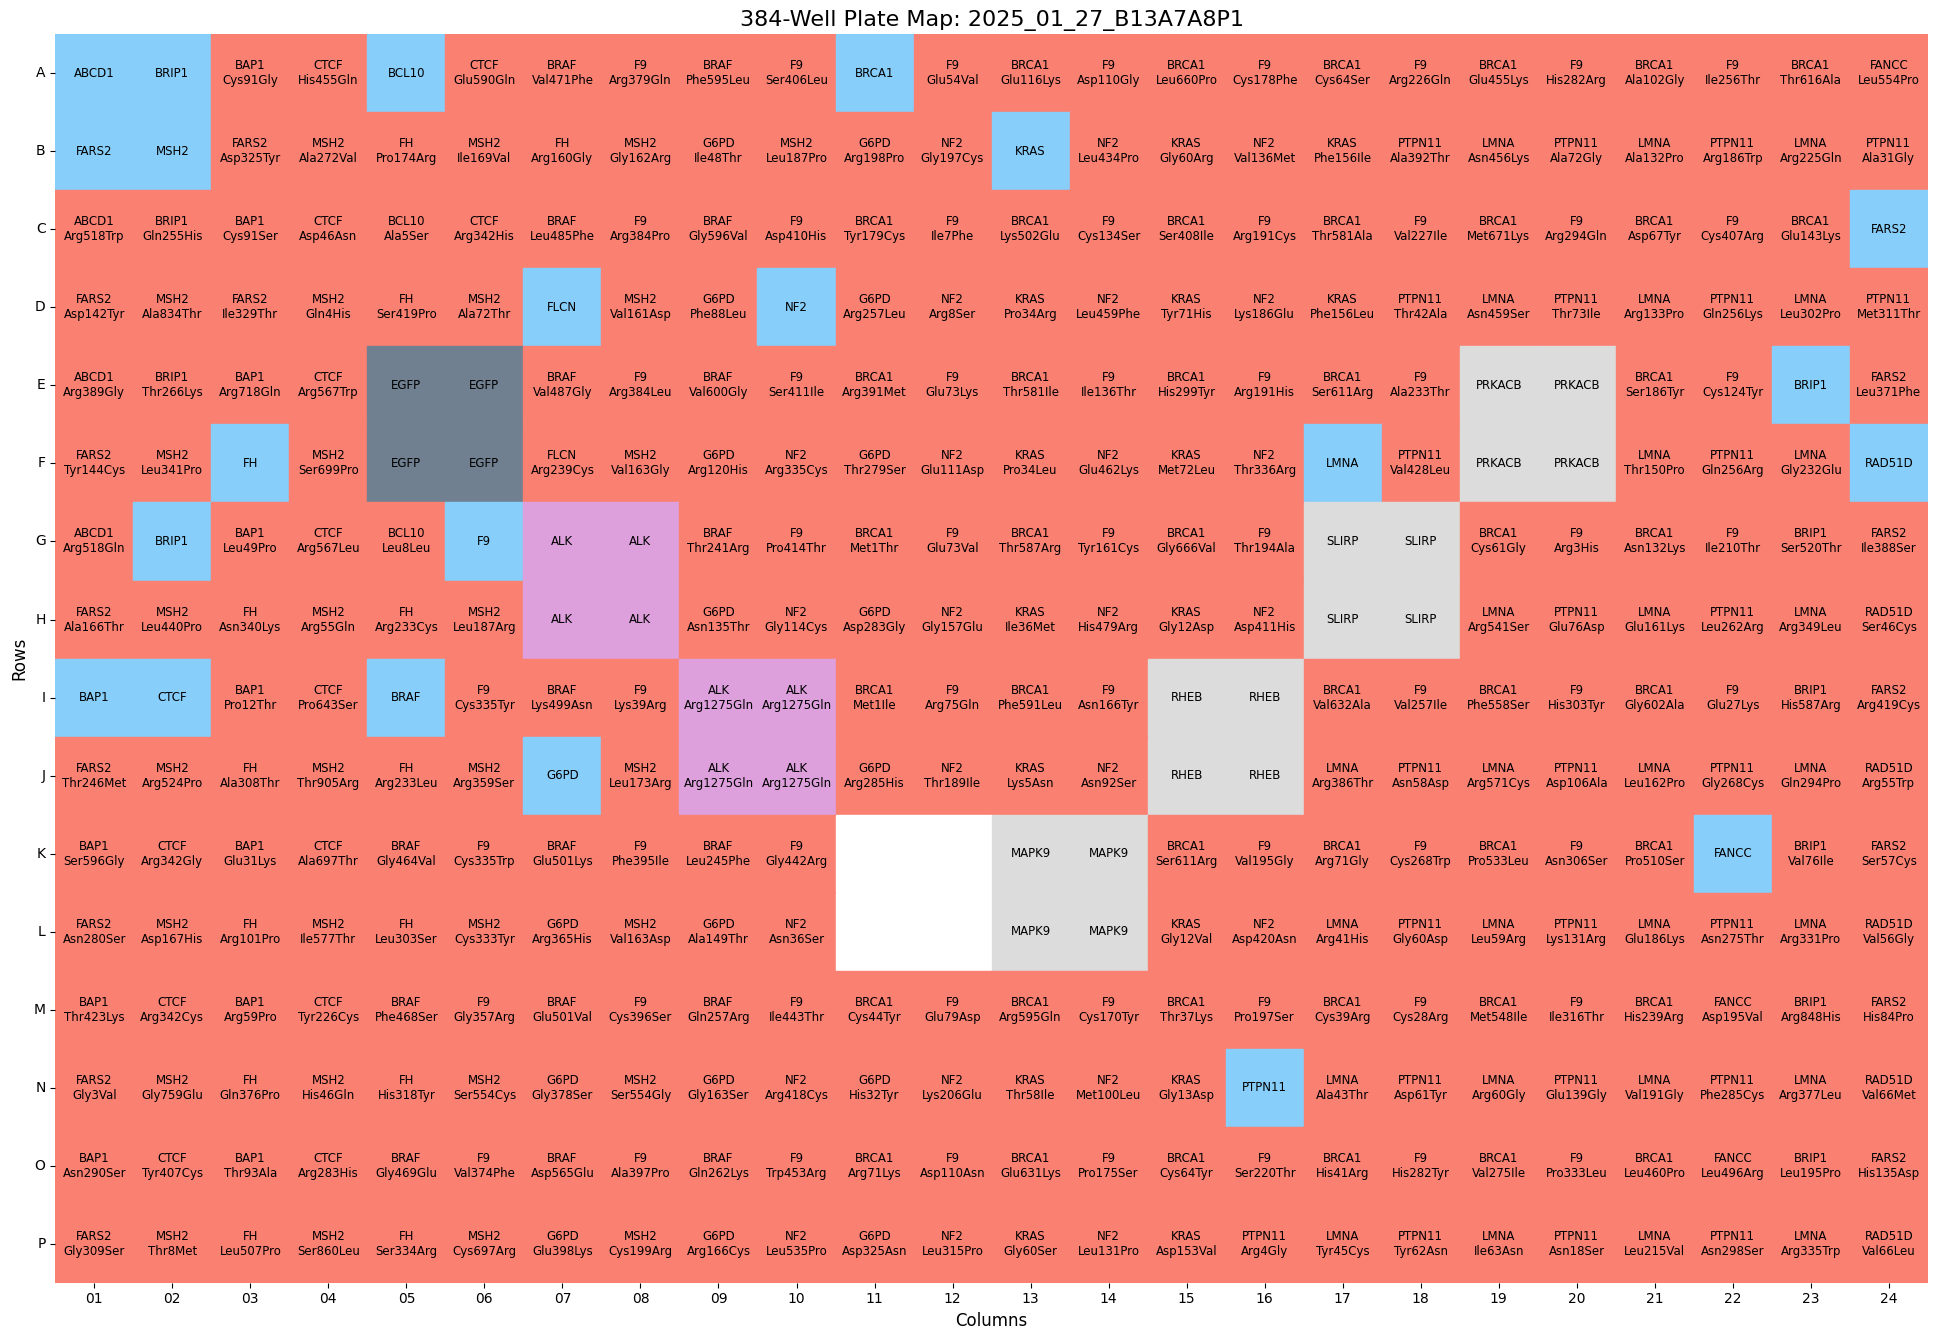

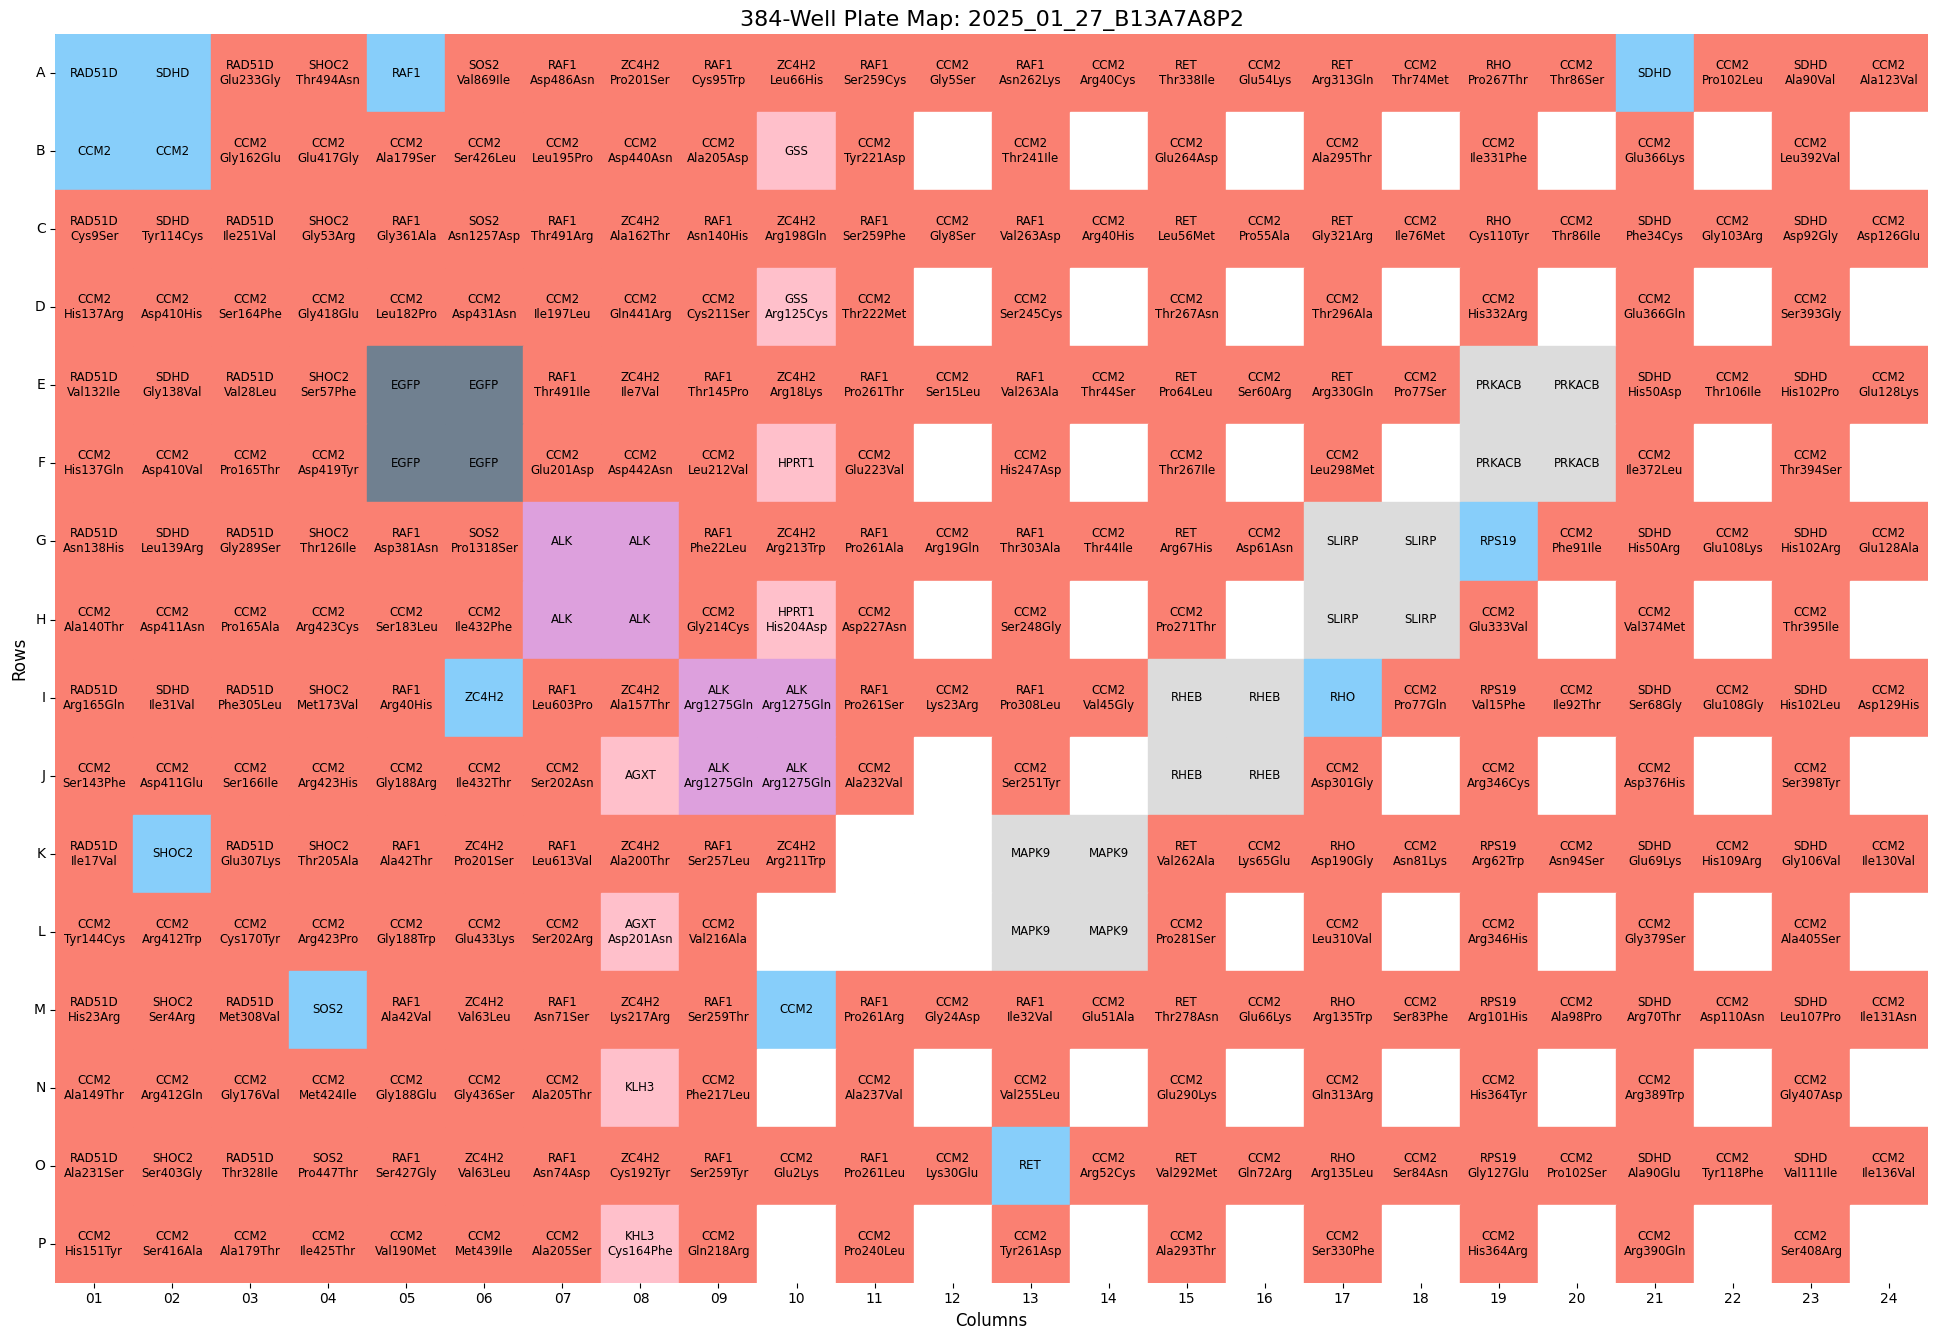

In [34]:
## clean up the meta file a little bit
## remove the unwanted '_' in the columns
meta_dat_b134_corrected = meta_dat_b134_corrected.with_columns(
    pl.when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
      .then(pl.col("gene_allele").str.replace(r"_$", ""))
      .otherwise(pl.col("gene_allele"))
      .alias("gene_allele") # Remove trailing "_"
)
## remove unnecessary weired chars
meta_dat_b134_corrected = meta_dat_b134_corrected.with_columns(
    pl.col("symbol").str.replace_all(r"[^a-zA-Z0-9_]", ""),#.alias("symbol"), ## remove unnessary chars
    pl.col("gene_allele").str.replace_all(r"[^a-zA-Z0-9_]", ""),#.alias("gene_allele"), ## remove unnessary chars
)
## correct eGFP to EGFP
meta_dat_b134_corrected = meta_dat_b134_corrected.with_columns(
    pl.col("symbol").str.replace('eGFP', 'EGFP'),#.alias("symbol"),
    pl.col("gene_allele").str.replace('eGFP', 'EGFP')#.alias("gene_allele")
)

plate_grid = plot_platemap(
    meta_dat_b134_corrected.filter(pl.col("imaging_plate_R1")=="B13A7A8P1_R1").filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"),
                          pl.col("imaging_well").alias("well_position")), 
    "2025_01_27_B13A7A8P1")

plate_grid = plot_platemap(
    meta_dat_b134_corrected.filter(pl.col("imaging_plate_R1")=="B13A7A8P2_R1").filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"),
                          pl.col("imaging_well").alias("well_position")), 
    "2025_01_27_B13A7A8P2")

In [35]:
# meta_dat_b134_corrected.write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/B13-14_metadata_update_cleaned.csv", separator=",")

### Old damaged platemaps

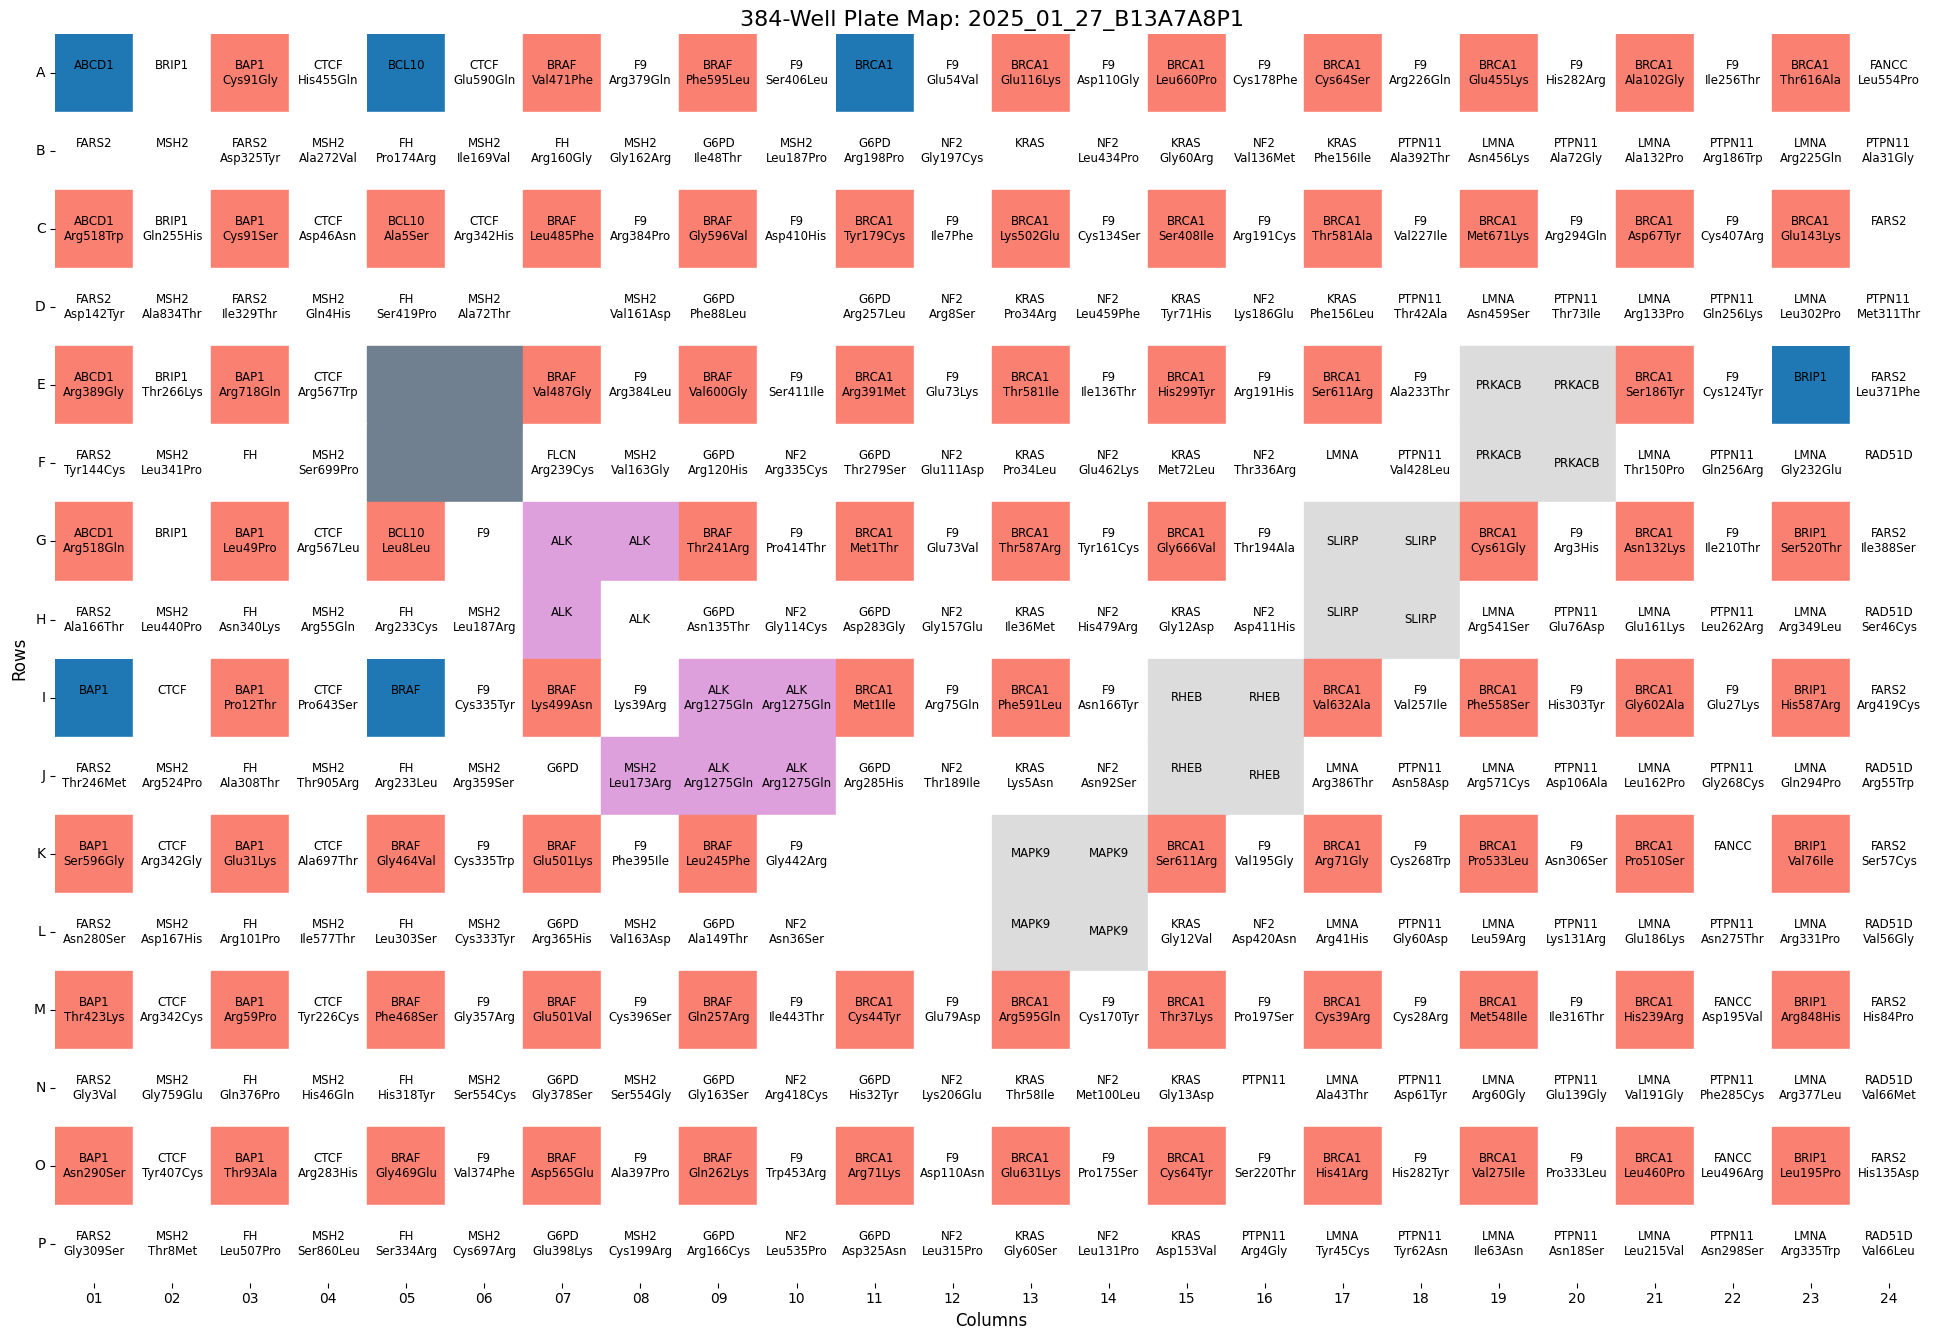

In [25]:
# batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2025_01_27_Batch_13/platemap/"
# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P1_T1.txt"
plate_map = pl.read_csv(Path(batch_dir_13) / Path(plate_map_id), separator='\t', has_header=True)
## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P1")

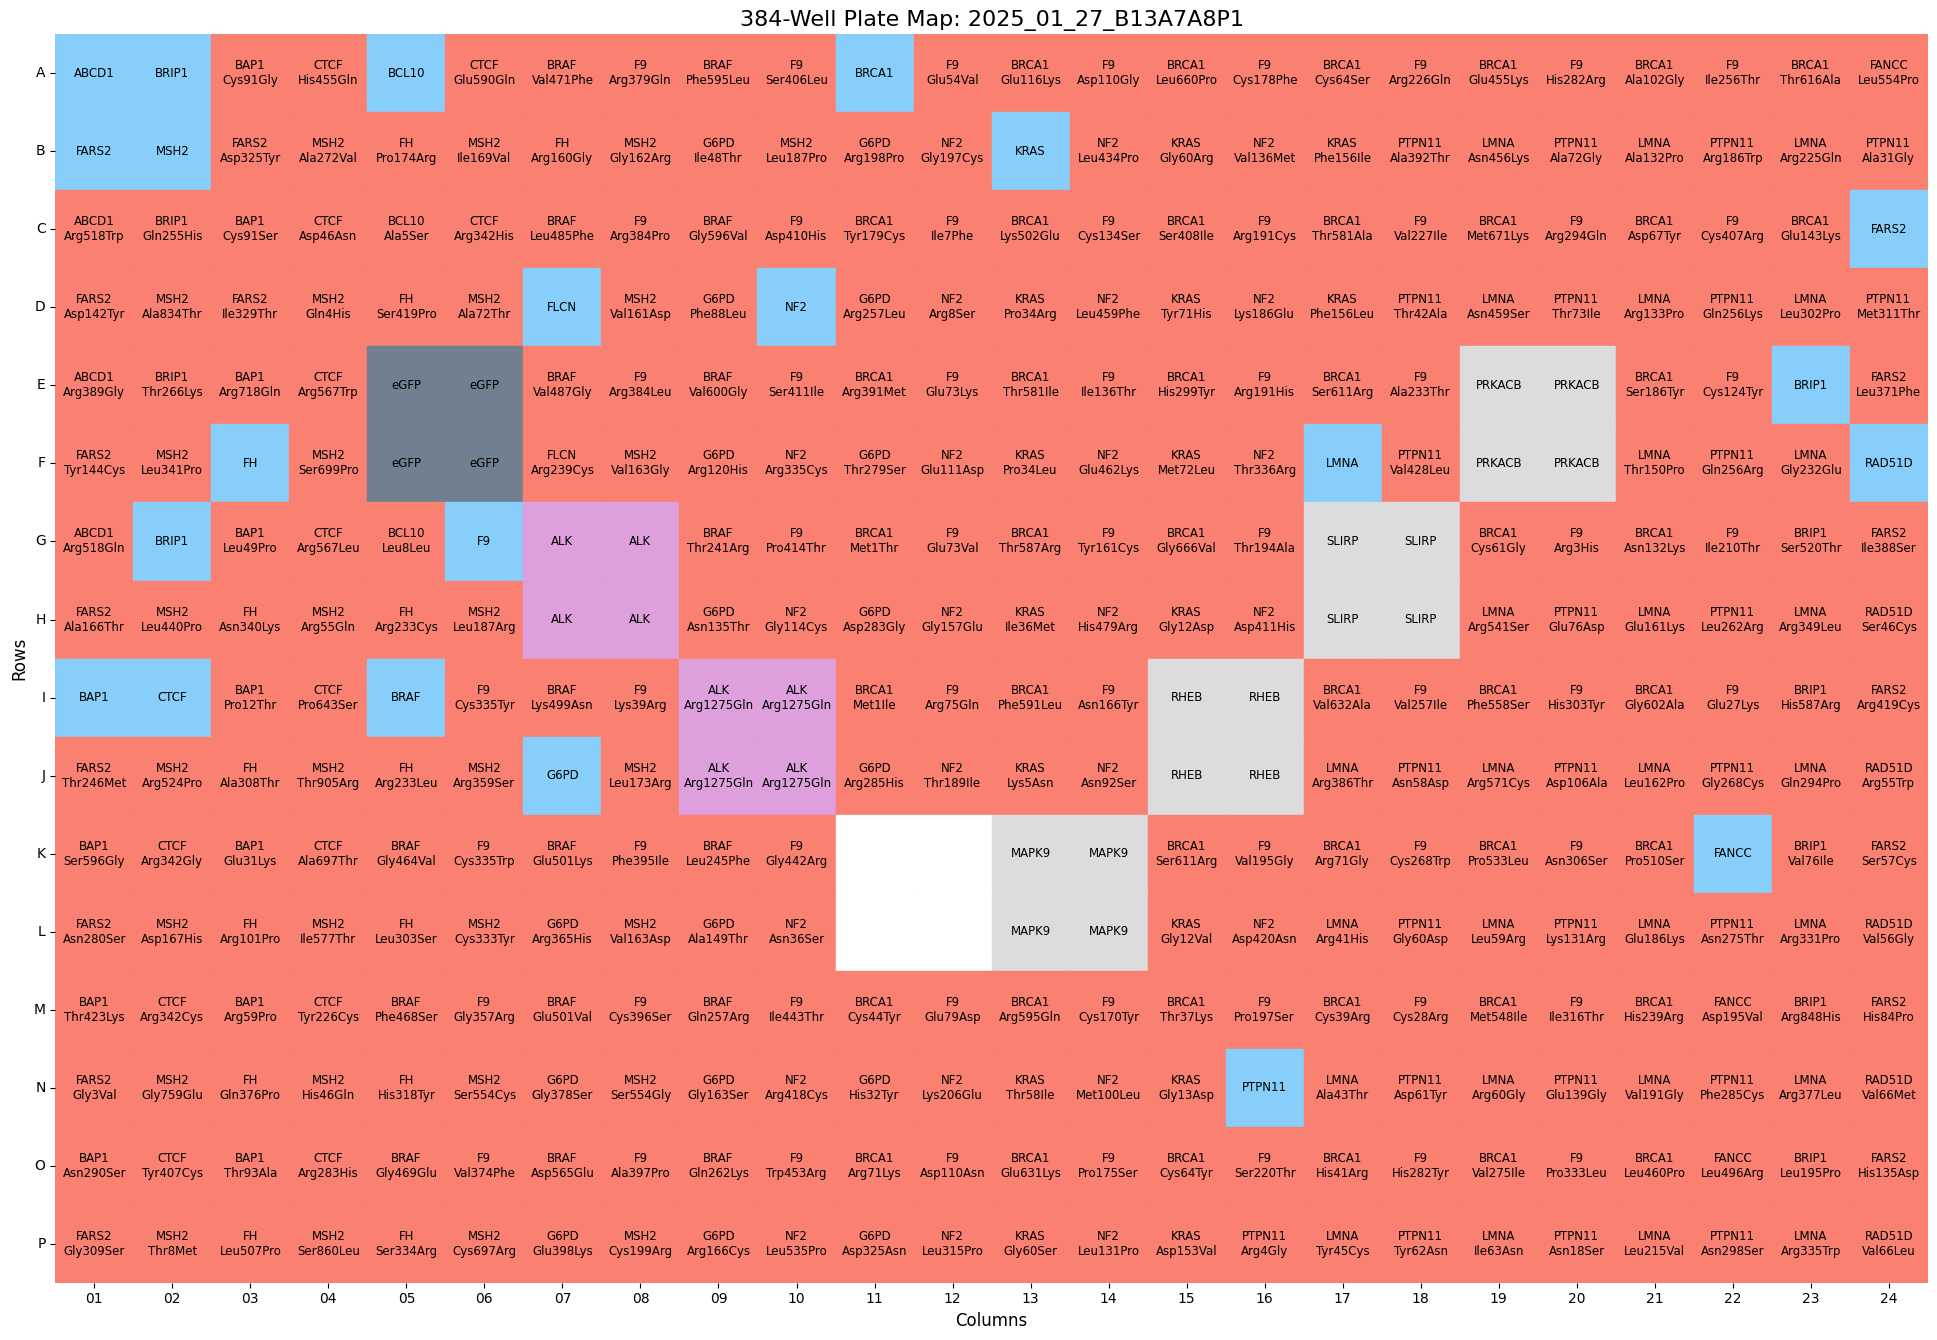

In [26]:
plate_map = plate_map.with_columns(
    # pl.col("symbol").alias("symbol_original"),
    # ## clean up the symbols first
    # pl.col("symbol").str.replace_all(r'[^a-zA-Z0-9]', '').alias("symbol"),
    # Condition 1: Keep "_" as is or fill the symbol if gene allele is missing by accident
    pl.when((pl.col("gene_allele")=="_")|(pl.col("gene_allele").is_null()&pl.col("symbol").is_not_null()))
        .then(pl.col("symbol"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.when((pl.col("gene_allele").is_in(PC))) #(pl.col("node_type").is_null())
        .then(pl.lit("PC"))
        .when((pl.col("gene_allele").is_in(NC))) #(pl.col("node_type").is_null())
        .then(pl.lit("NC"))
        # .when((pl.col("gene_allele").is_in(cPC))) #(pl.col("node_type").is_null())
        # .then(pl.lit("cPC"))
        .when(pl.col("aa_change").is_not_null()) ## manually handle a special case
        .then(pl.lit("allele"))
        .when((pl.col("aa_change").is_null())&(pl.col("symbol").is_not_null())&(~pl.col("symbol").is_in(PC))&(~pl.col("symbol").is_in(NC))&(~pl.col("symbol").str.to_uppercase().is_in(TC))) ## (pl.col("node_type").is_null())&
        .then(pl.lit("disease_wt"))
        .when(pl.col("node_type").is_not_null())
        .then(pl.col("node_type"))
        .when((pl.col("symbol").str.to_uppercase().is_in(TC))) #(pl.col("node_type").is_null())
        .then(pl.lit("TC"))
        .alias("control_type")
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.lit("control"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.lit("allele"))
    #     .otherwise(pl.lit("disease_wt"))
    #     .alias("control_type"),
)
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P1")

In [27]:
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P1_T1.txt", separator="\t")

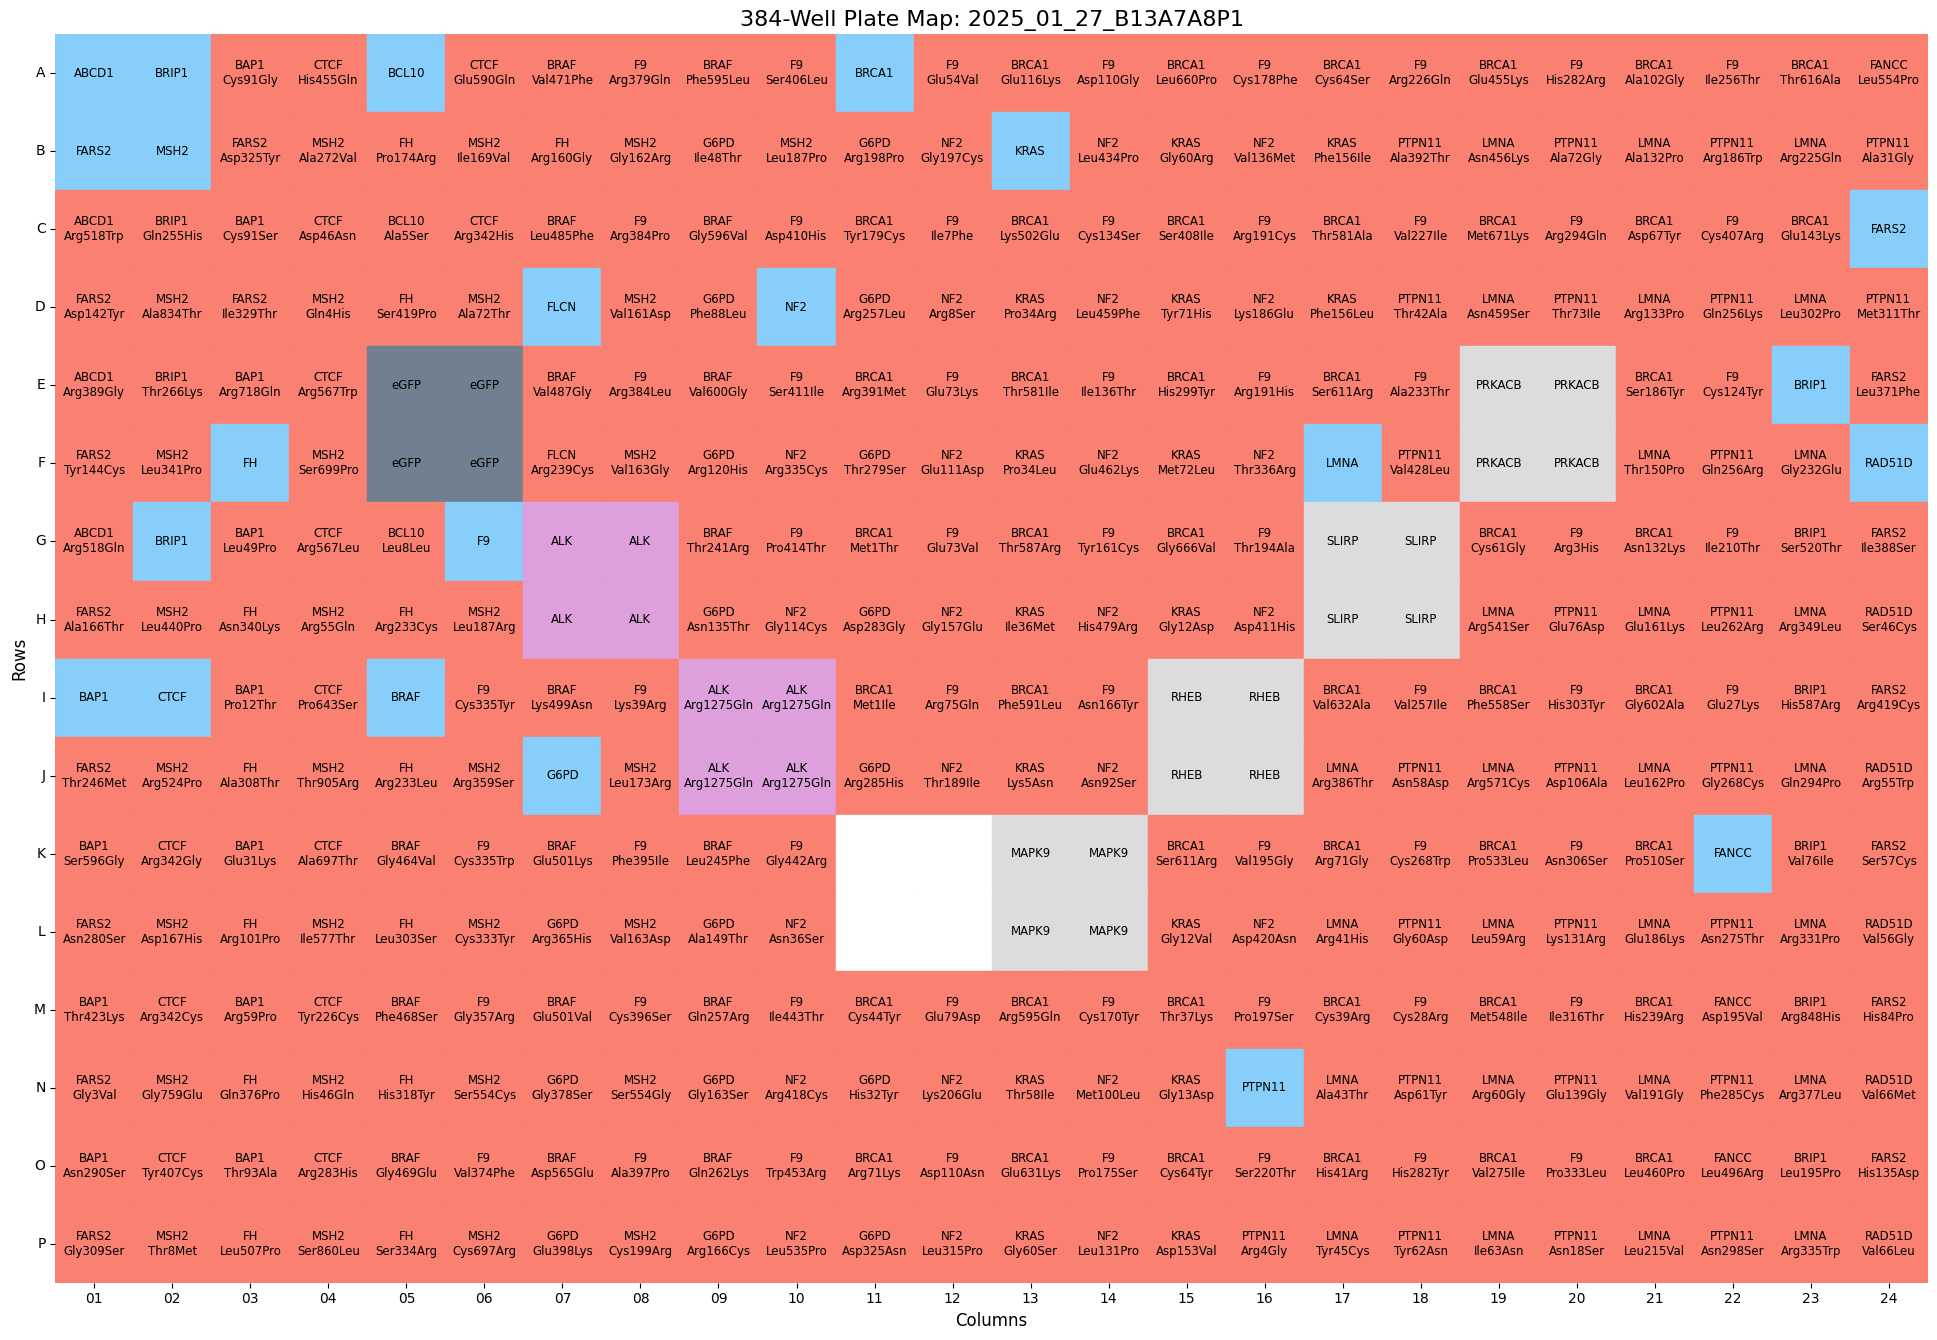

In [4]:
# plate_map.filter(pl.col("well_position")=="E19")
# plate_map.filter(pl.col("well_position")=="E19")
# plate_map.filter(pl.col("symbol")=="FLCN")
# plate_map.filter(pl.col("symbol").str.to_uppercase().is_in(TC))

batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/7.analysis_runxi/output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/"
# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P1_T1.txt"
plate_map = pl.read_csv(Path(batch_dir) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P1")

### Second plate

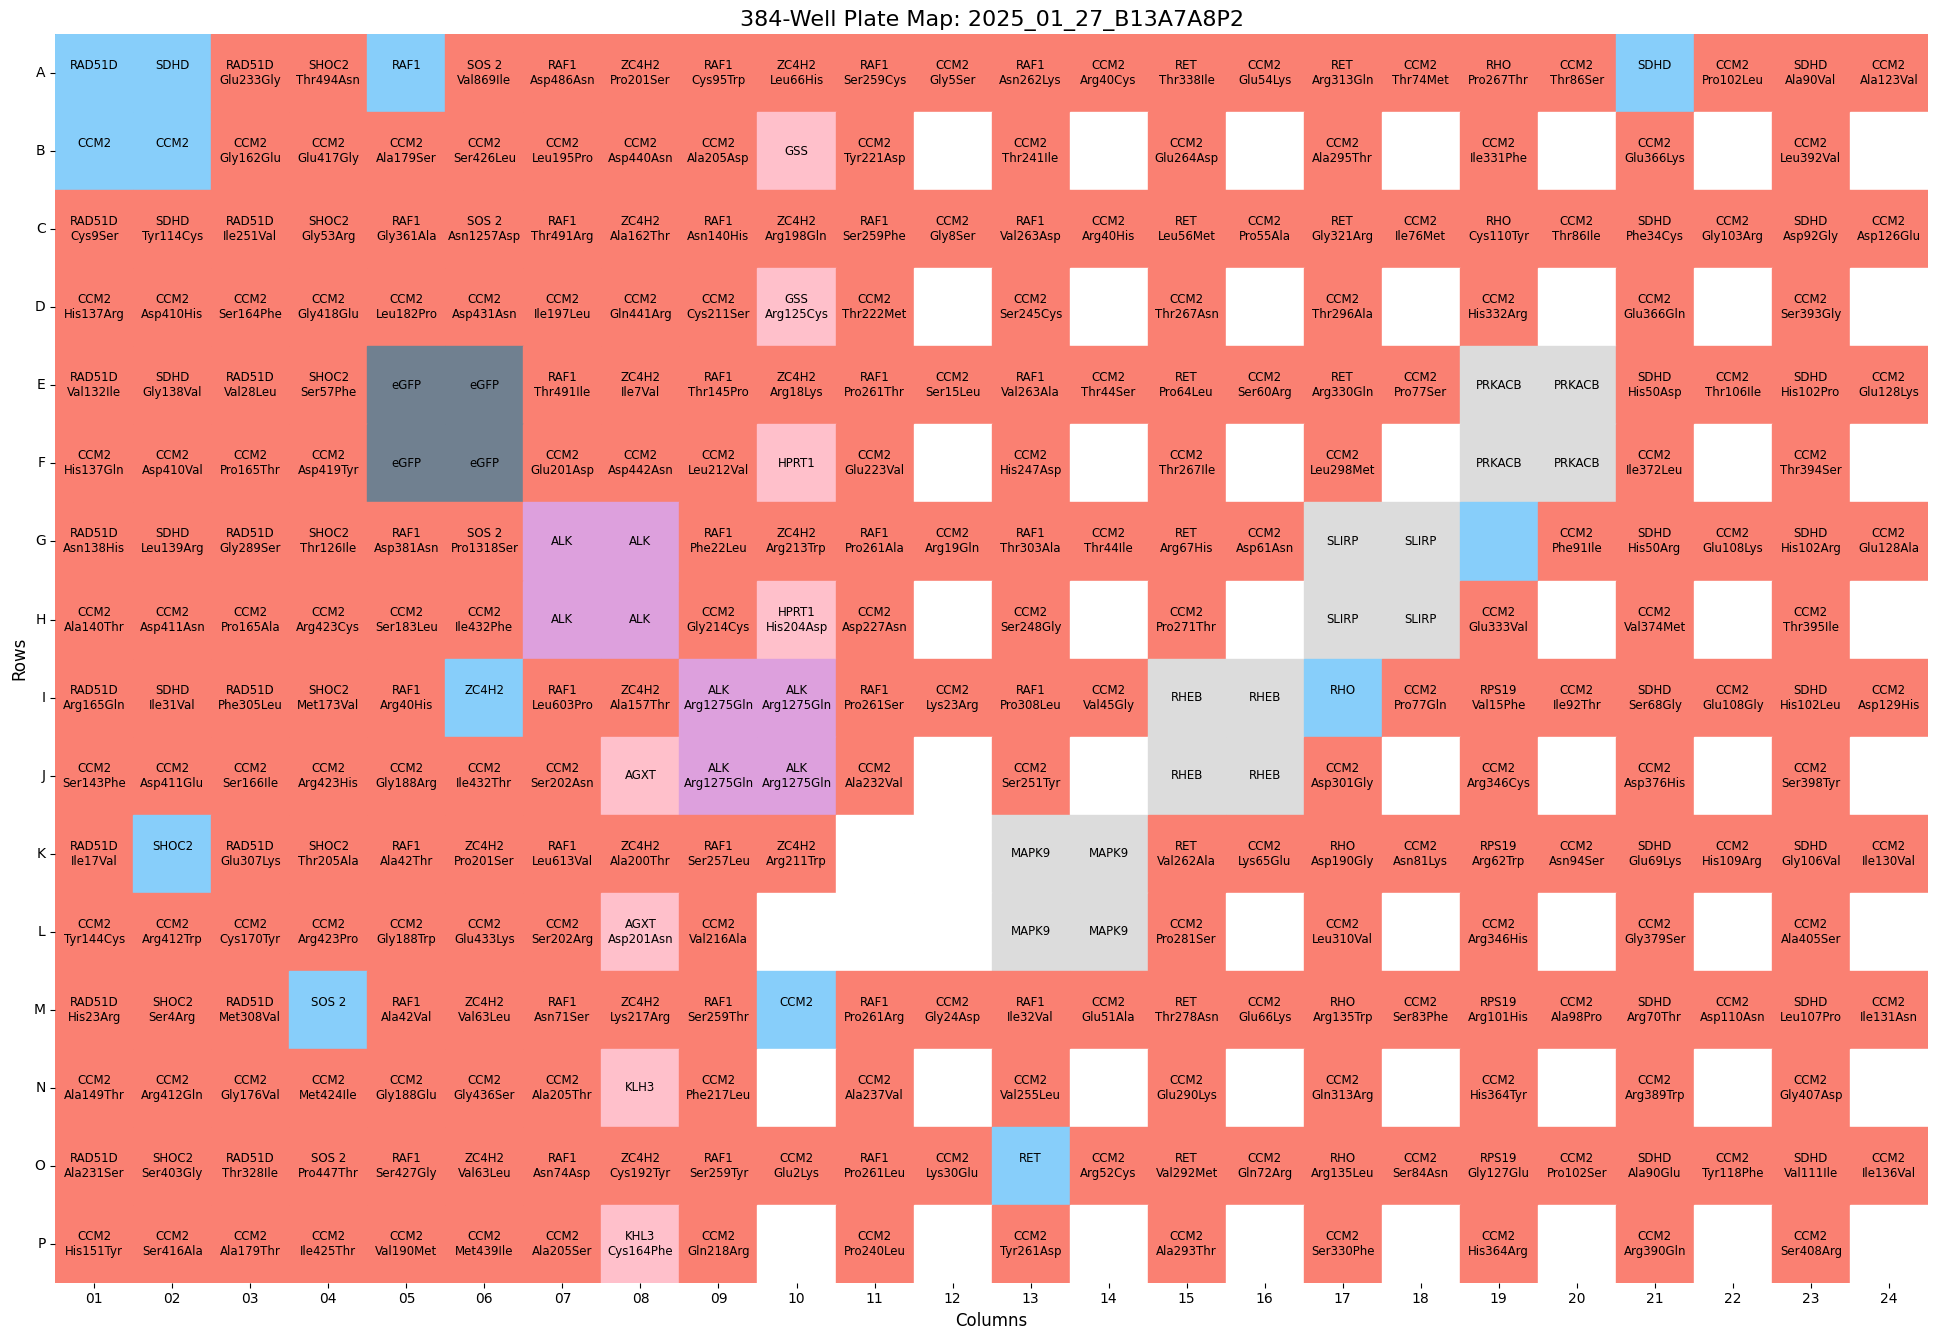

In [24]:
batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2025_01_27_Batch_13/platemap/"

# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P2_T1.txt"
plate_map = pl.read_csv(Path(batch_dir) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P2")

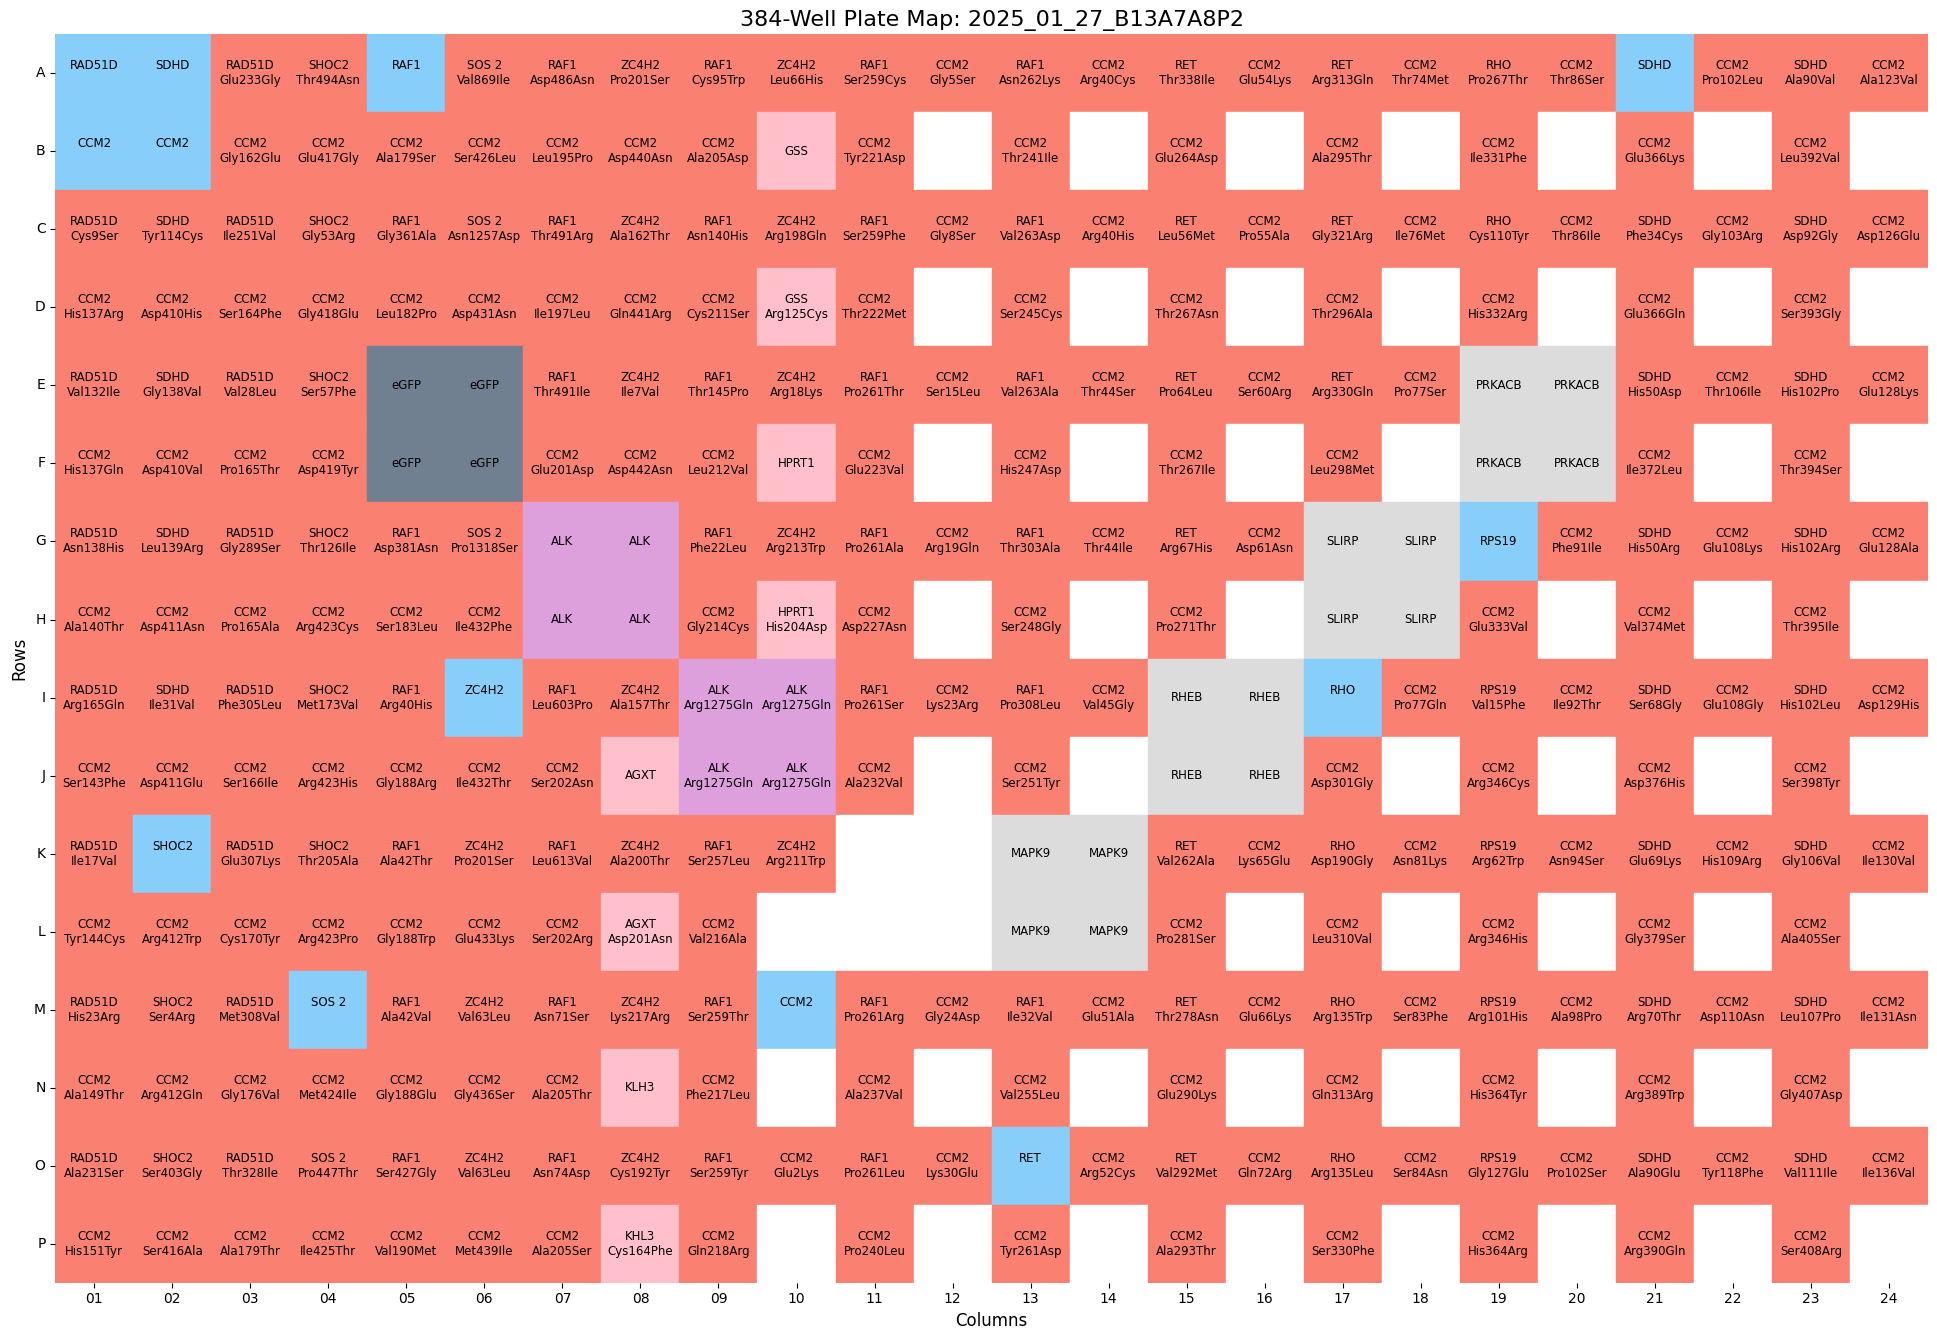

In [5]:
batch_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/7.analysis_runxi/output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/"
# for plate_map_id in os.listdir(batch_dir):
plate_map_id = "2025_01_27_B13A7A8P2_T1.txt"
plate_map = pl.read_csv(Path(batch_dir) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(
                ~pl.all_horizontal(pl.all().is_null())
            ).with_columns(pl.col("node_type").alias("control_type"))
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P2")

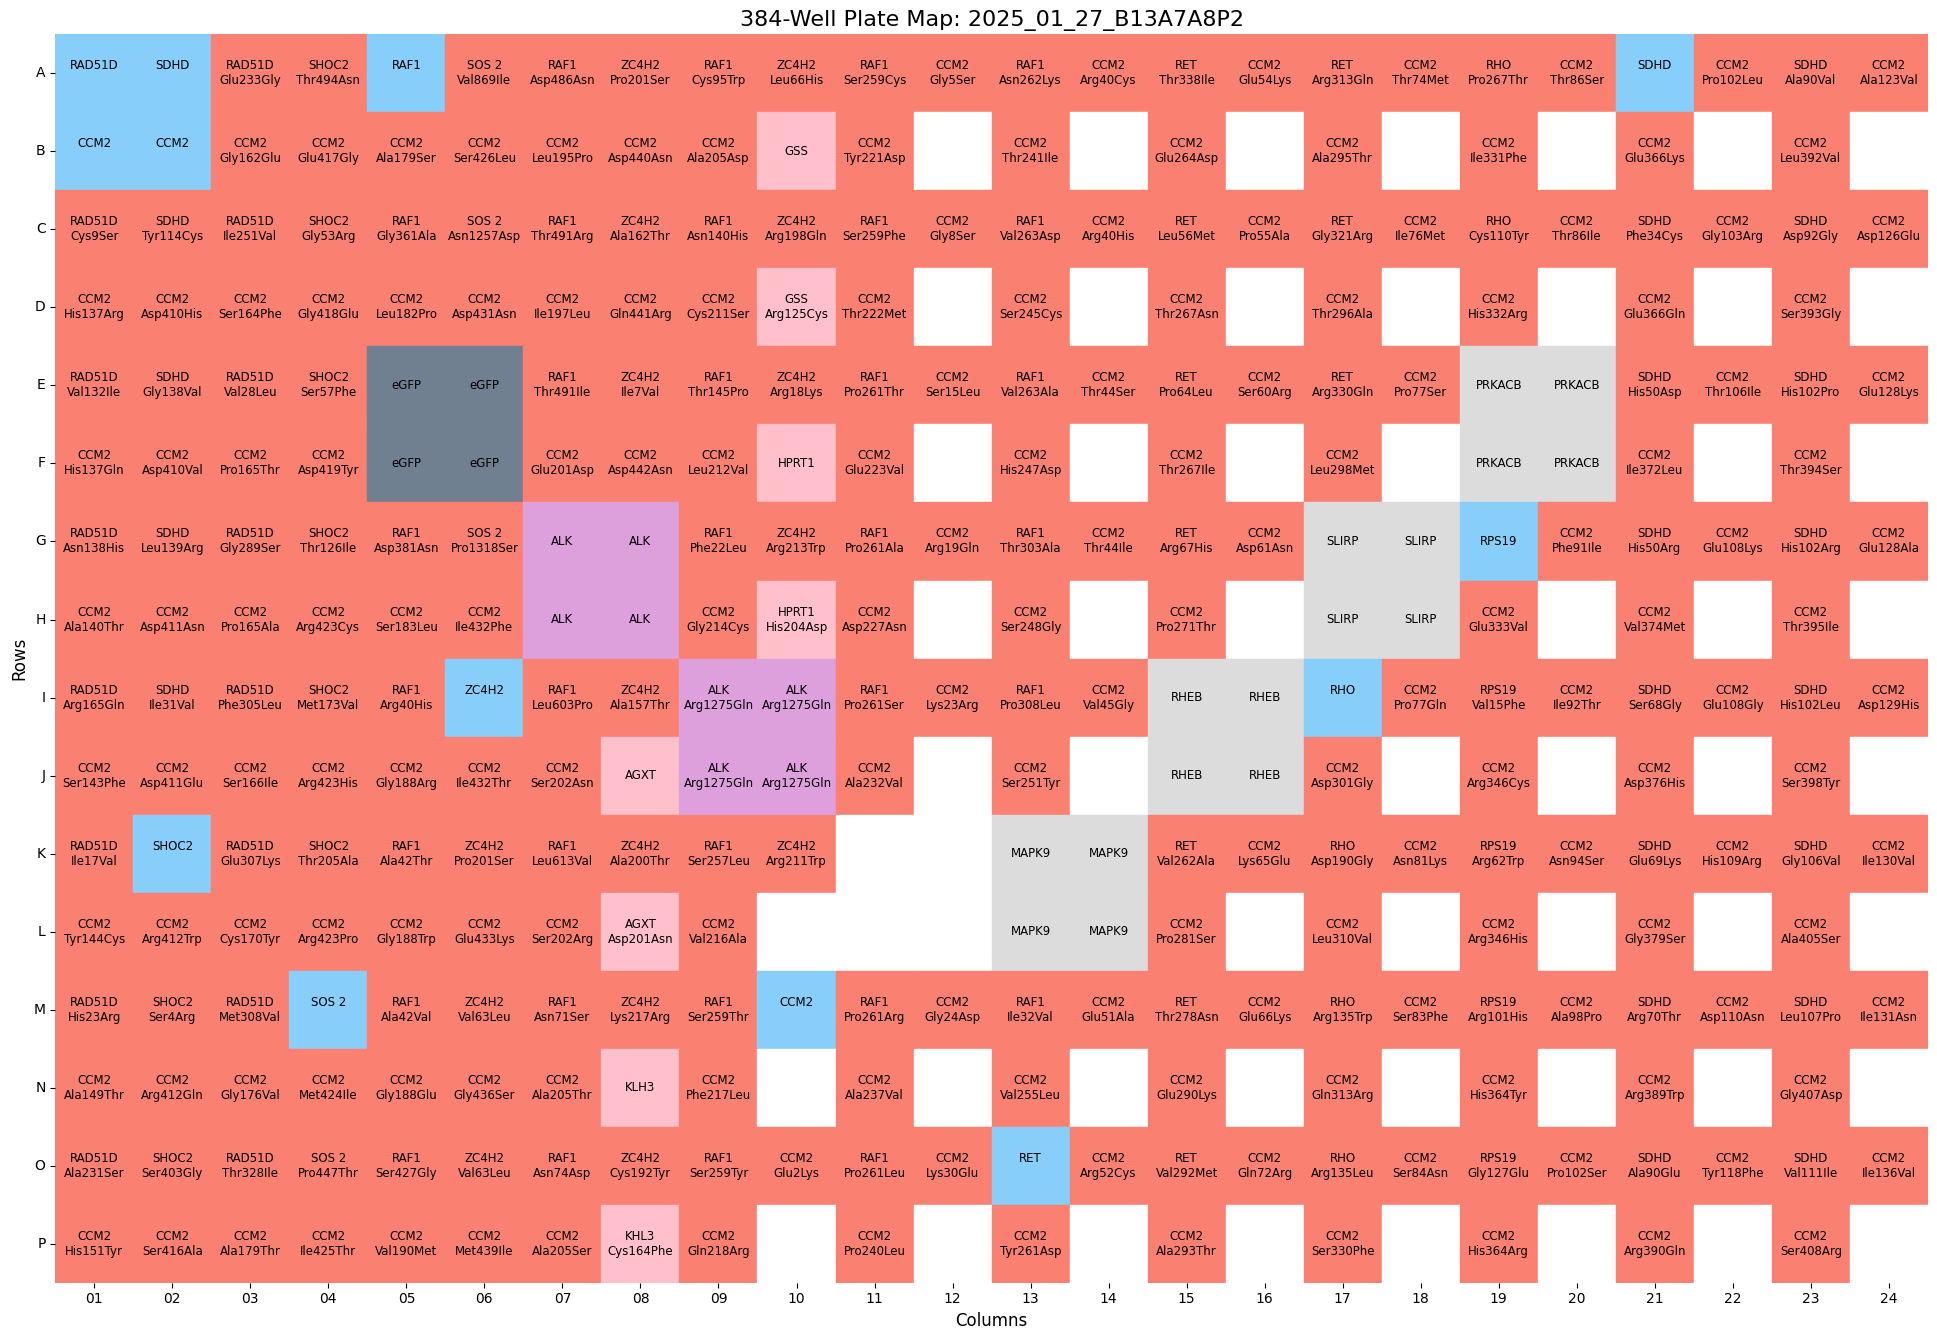

In [18]:
plate_map = plate_map.with_columns(
    # Condition 1: Keep "_" as is or fill the symbol if gene allele is missing by accident
    pl.when(pl.col("symbol").is_not_null()&pl.col("gene_allele").is_null())
        .then(pl.col("symbol"))
        .otherwise(pl.col("gene_allele"))
        .alias("gene_allele")
    # pl.when((pl.col("gene_allele")=="_")|(pl.col("gene_allele").is_null()&pl.col("symbol").is_not_null()))
    #     .then(pl.col("symbol"))
    #     .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
    #     .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
    #     .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
    #     .alias("gene_allele"),  # Replace the original column,
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.col("gene_allele"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
    #     .otherwise(pl.col("gene_allele"))
    #     .alias("symbol"),
    # pl.when(pl.col("aa_change").is_not_null()) ## manually handle a special case
    #     .then(pl.lit("allele"))
    #     .when((pl.col("node_type").is_null())&(pl.col("aa_change").is_null())&(pl.col("symbol").is_not_null())&(~pl.col("symbol").is_in(PC)))
    #     .then(pl.lit("disease_wt"))
    #     .when((pl.col("node_type").is_null())&(pl.col("symbol").is_in(PC)))
    #     .then(pl.lit("PC"))
    #     # .when(pl.col("node_type").is_not_null())
    #     # .then(pl.col("node_type"))
    #     .alias("control_type")
)
plate_grid = plot_platemap(plate_map, "2025_01_27_B13A7A8P2")

In [21]:
# plate_grid.filter(pl.col("well_position")=="G19")

In [22]:
# plate_grid.with_columns(pl.col("control_type").alias("node_type")).select(plate_map.columns).write_csv("../../output/meta_correct_batch13-14/2025_01_27_Batch_13/platemap/2025_01_27_B13A7A8P2_T1.txt", separator="\t")

## Batch 9/10

### Confocal

Number of unique alleles: ['EGFP', 'F9_Glu27Lys', 'ALK_Arg1275Gln', 'PRKACB', 'LMNA', 'CTCF_Tyr226Cys', 'RPS19', 'RPS19_Val15Phe', 'CTCF_His455Gln', 'LMNA_Arg349Leu', 'G6PD_Glu398Lys', 'BCL10_Leu8Leu', 'F9_Glu73Val', 'G6PD', 'F9_Trp453Arg', 'FLCN_Arg239Cys', 'RPS19_Arg62Trp', 'LMNA_Arg331Pro', 'LMNA_Arg60Gly', 'FANCC_Asp195Val', 'LMNA_Glu186Lys', 'CTCF_Ala697Thr', 'F9_Pro333Leu', 'F9_Cys396Ser', '_', 'F9_Arg294Gln', 'RPS19_Arg101His', 'LMNA_Thr150Pro', 'F9_Ile256Thr', 'MRE11', 'MAPK9', 'F9_Cys170Tyr', 'F9_Gly357Arg', 'F9_Cys28Arg', 'CTCF_Arg342Cys', 'CTCF', 'CTCF_Asp46Asn', 'SLIRP', 'F9_Arg191His', 'F9_Cys268Trp', 'FANCC_Leu554Pro', 'CTCF_Glu590Gln', 'MRE11_Arg202Gly', 'LMNA_Tyr45Cys', 'LMNA_Ala132Pro', 'RPS19_Gly127Glu', 'CTCF_Arg342His', 'CTCF_Arg567Leu', 'CTCF_Arg342Gly', 'F9_Glu73Lys', 'CTCF_Tyr407Cys', 'F9_Arg384Pro', 'FANCC', 'F9_Arg226Gln', 'ALK', 'F9_Asp110Asn', 'LMNA_Arg541Ser', 'F9_Asp410His', 'LMNA_Gly232Glu', 'F9_His303Tyr', 'LMNA_Arg571Cys', 'F9_Asn306Ser', 'LMNA_Ala43Thr'

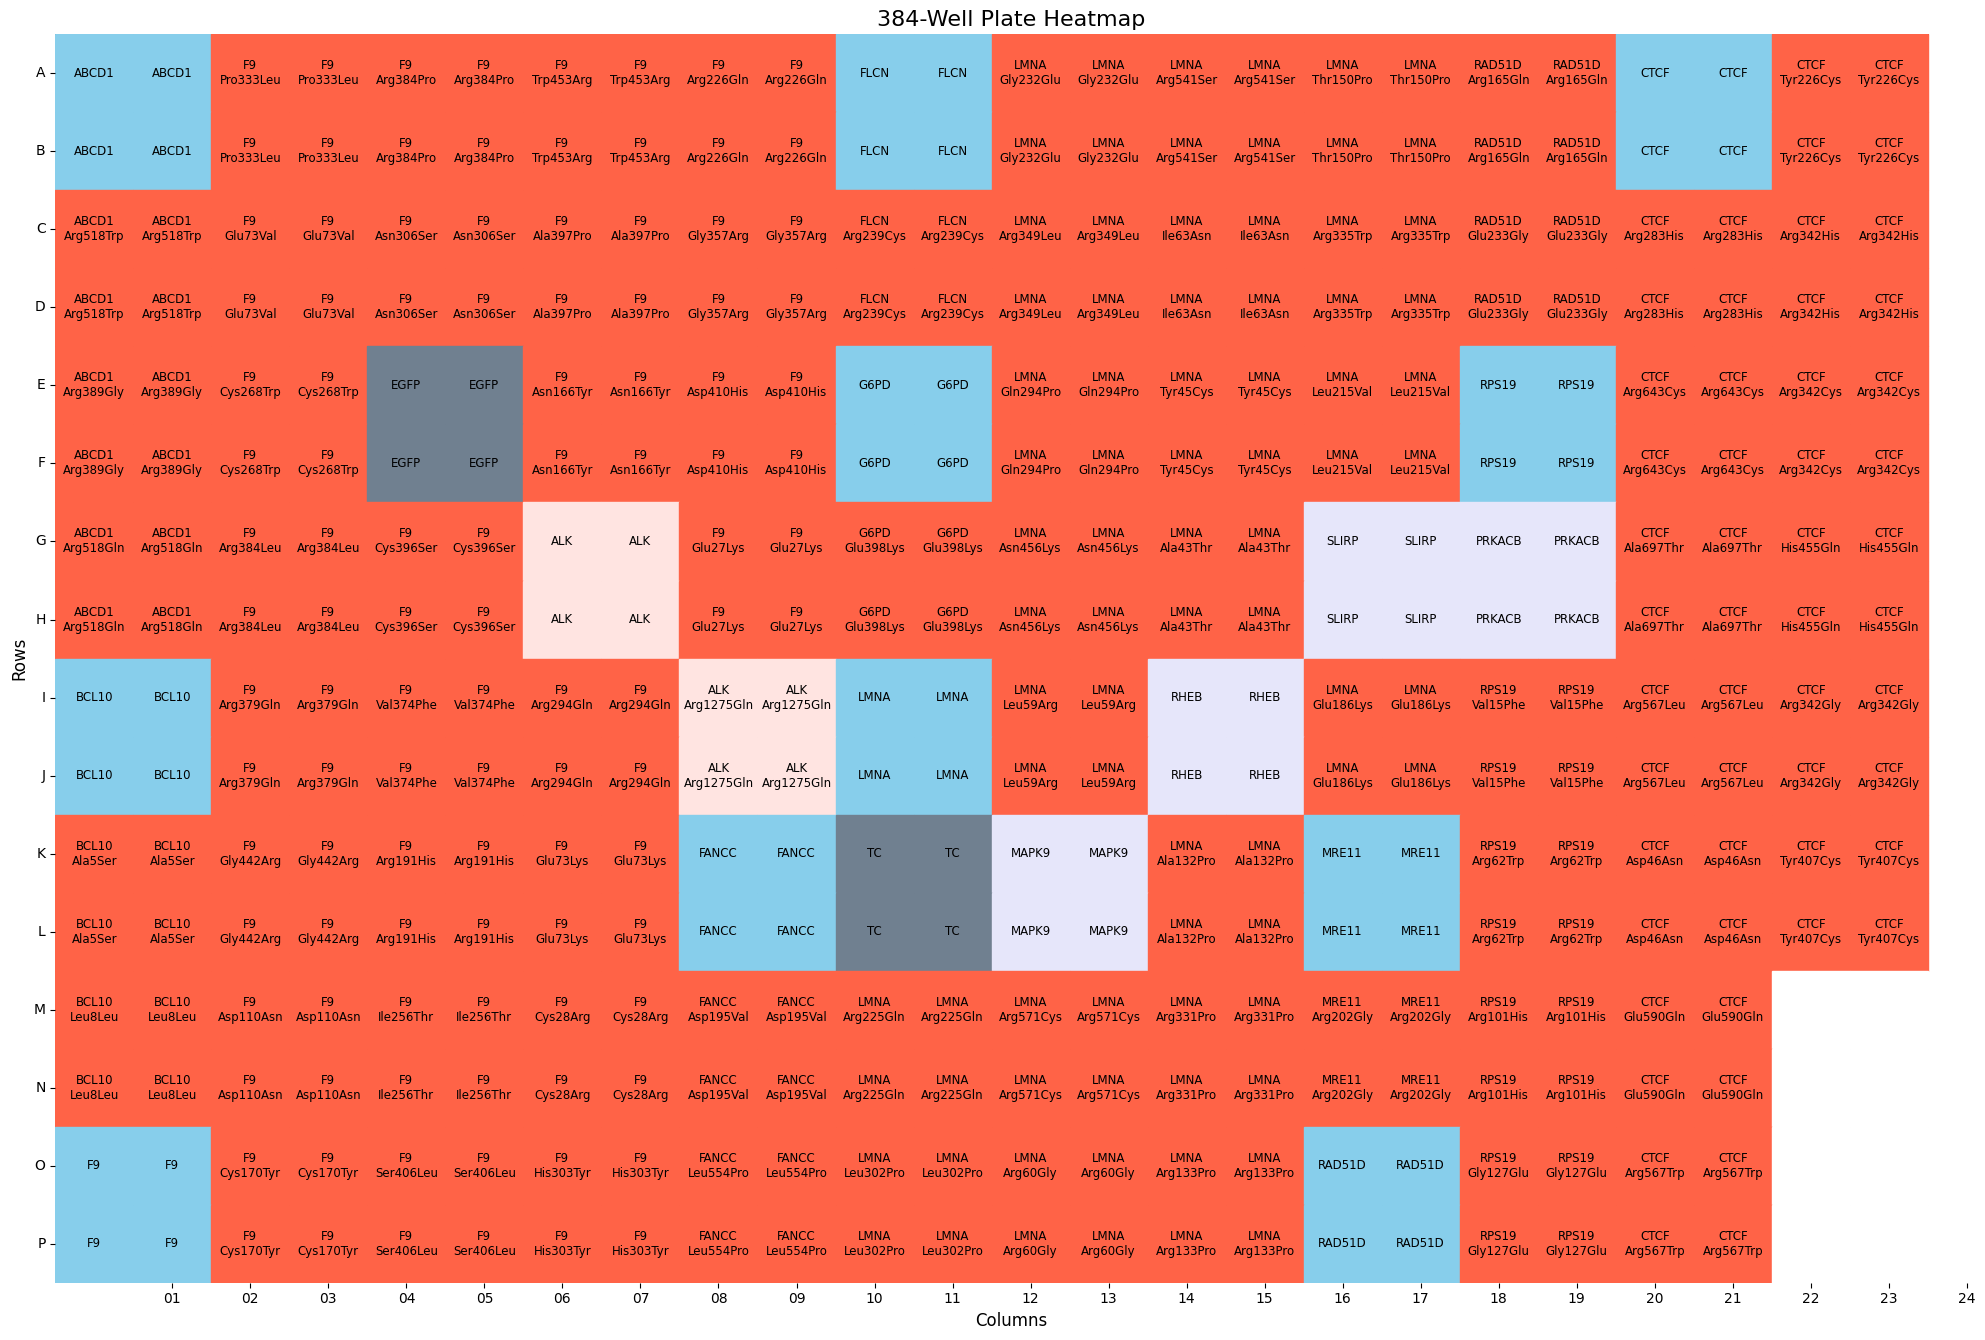

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_well_id,dest_plate,dest_well,dest_well_id,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,ccsb_mutation_id,nt_change,aa_change,technical_replicate,allele_set,imaging_plate,batch1,batch2,vector,control_type,color,label
u64,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""","""P01""","""A01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T1""","""A01""",1,"""A01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,1,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
1,"""01""","""""","""B""","""01""","""P01""","""B01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T3""","""A01""",1,"""B01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,3,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
2,"""01""","""""","""C""","""01""","""P01""","""C01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T1""","""B01""",2,"""C01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
3,"""01""","""""","""D""","""01""","""P01""","""D01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T3""","""B01""",2,"""D01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",3,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
4,"""01""","""""","""E""","""01""","""P01""","""E01""","""ABCD1""","""ABCD1_Arg389Gly""","""CAVA_CP_P01_Prep2""","""C01""",3,"""CAVA_CP_Array_P01_T1""","""C01""",3,"""E01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007023""","""1165C>G""","""Arg389Gly""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg389Gly"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11,"""24""","""""","""L""","""24""","""P01""","""L24""","""CTCF""","""CTCF_Tyr407Cys""","""CAVA_CP_P02""","""H04""",32,"""CAVA_CP_Array_P01_T4""","""F12""",94,"""L24""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",6173,"""CCSBVarC010870""","""1220A>G""","""Tyr407Cys""",4,6,1,9,10,594,"""allele""","""allele""","""CTCF Tyr407Cys"""
12,"""24""","""""","""M""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
13,"""24""","""""","""N""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""


In [36]:
batch9_platemap_confo = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_9_confocal/platemap"
plate_map_id = "B9A6R1_P01.txt"
plate_map = pl.read_csv(Path(batch9_platemap_confo) / Path(plate_map_id), separator='\t', has_header=True)

## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map = plate_map.filter(~pl.all_horizontal(pl.all().is_null()))
# print(plate_map.shape

column_name = "gene_allele"
plate_map = plate_map.with_columns(
    pl.when(pl.col("gene_allele") == "_")  # Condition 1: Keep "_" as is
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.col("node_type").alias("control_type")
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.lit("control"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.lit("allele"))
    #     .otherwise(pl.lit("disease_wt"))
    #     .alias("control_type"),
)

# print(plate_map.select(pl.col(column_name).unique()))
# print(plate_map.select(pl.col("gene_allele").unique()))
# # print(plate_map.select(pl.col("symbol").unique()))
plot_platemap(plate_map)

(236, 24)
Number of unique alleles: ['NF2_Lys206Glu', 'NF2_Met29Ile', 'ZC4H2_Arg211Trp', 'ALK', 'NF2_Ser489Gly', 'ZC4H2_Arg198Gln', '_', 'NF2_Asn220Tyr', 'ZC4H2_Lys217Arg', 'NF2_Asn92Ser', 'NF2_Met100Leu', 'ZC4H2_IIe7Val', 'NF2_Leu459Phe', 'NF2_Arg471Gly', 'ZC4H2_Ala200Thr', 'ZC4H2_Arg67Gln', 'NF2_Val136Met', 'NF2_Asp420Asn', 'NF2_Leu434Pro', 'NF2_Leu535Pro', 'EGFP', 'NF2_Leu315Pro', 'NF2_Thr336Arg', 'NF2_Glu111Asp', 'ZC4H2_Ala157Thr', 'NF2_Pro410Leu', 'ZC4H2_Val63Leu', 'NF2_Glu462Lys', 'ZC4H2_Leu66His', 'ALK_Arg1275Gln', 'NF2_Glu344Ala', None, 'NF2_Gly157Glu', 'NF2_Arg335Cys', 'NF2_Leu58Pro', 'NF2_Asp411His', 'NF2_Arg418Cys', 'NF2_Lys186Glu', 'ZC4H2_Ala162Thr', 'NF2_Leu277Pro', 'NF2_Pro19Arg', 'ZC4H2_Cys192Tyr', 'NF2_Leu131Pro', 'NF2_Gln64Pro', 'NF2_Arg8Ser', 'ZC4H2', 'ZC4H2_Pro201Ser', 'NF2_Thr189Ile', 'NF2_Asn36Ser', 'NF2_Leu375Arg', 'MAPK9', 'NF2', 'ZC4H2_Arg18Lys', 'NF2_His479Arg', 'ZC4H2_Arg213Trp']


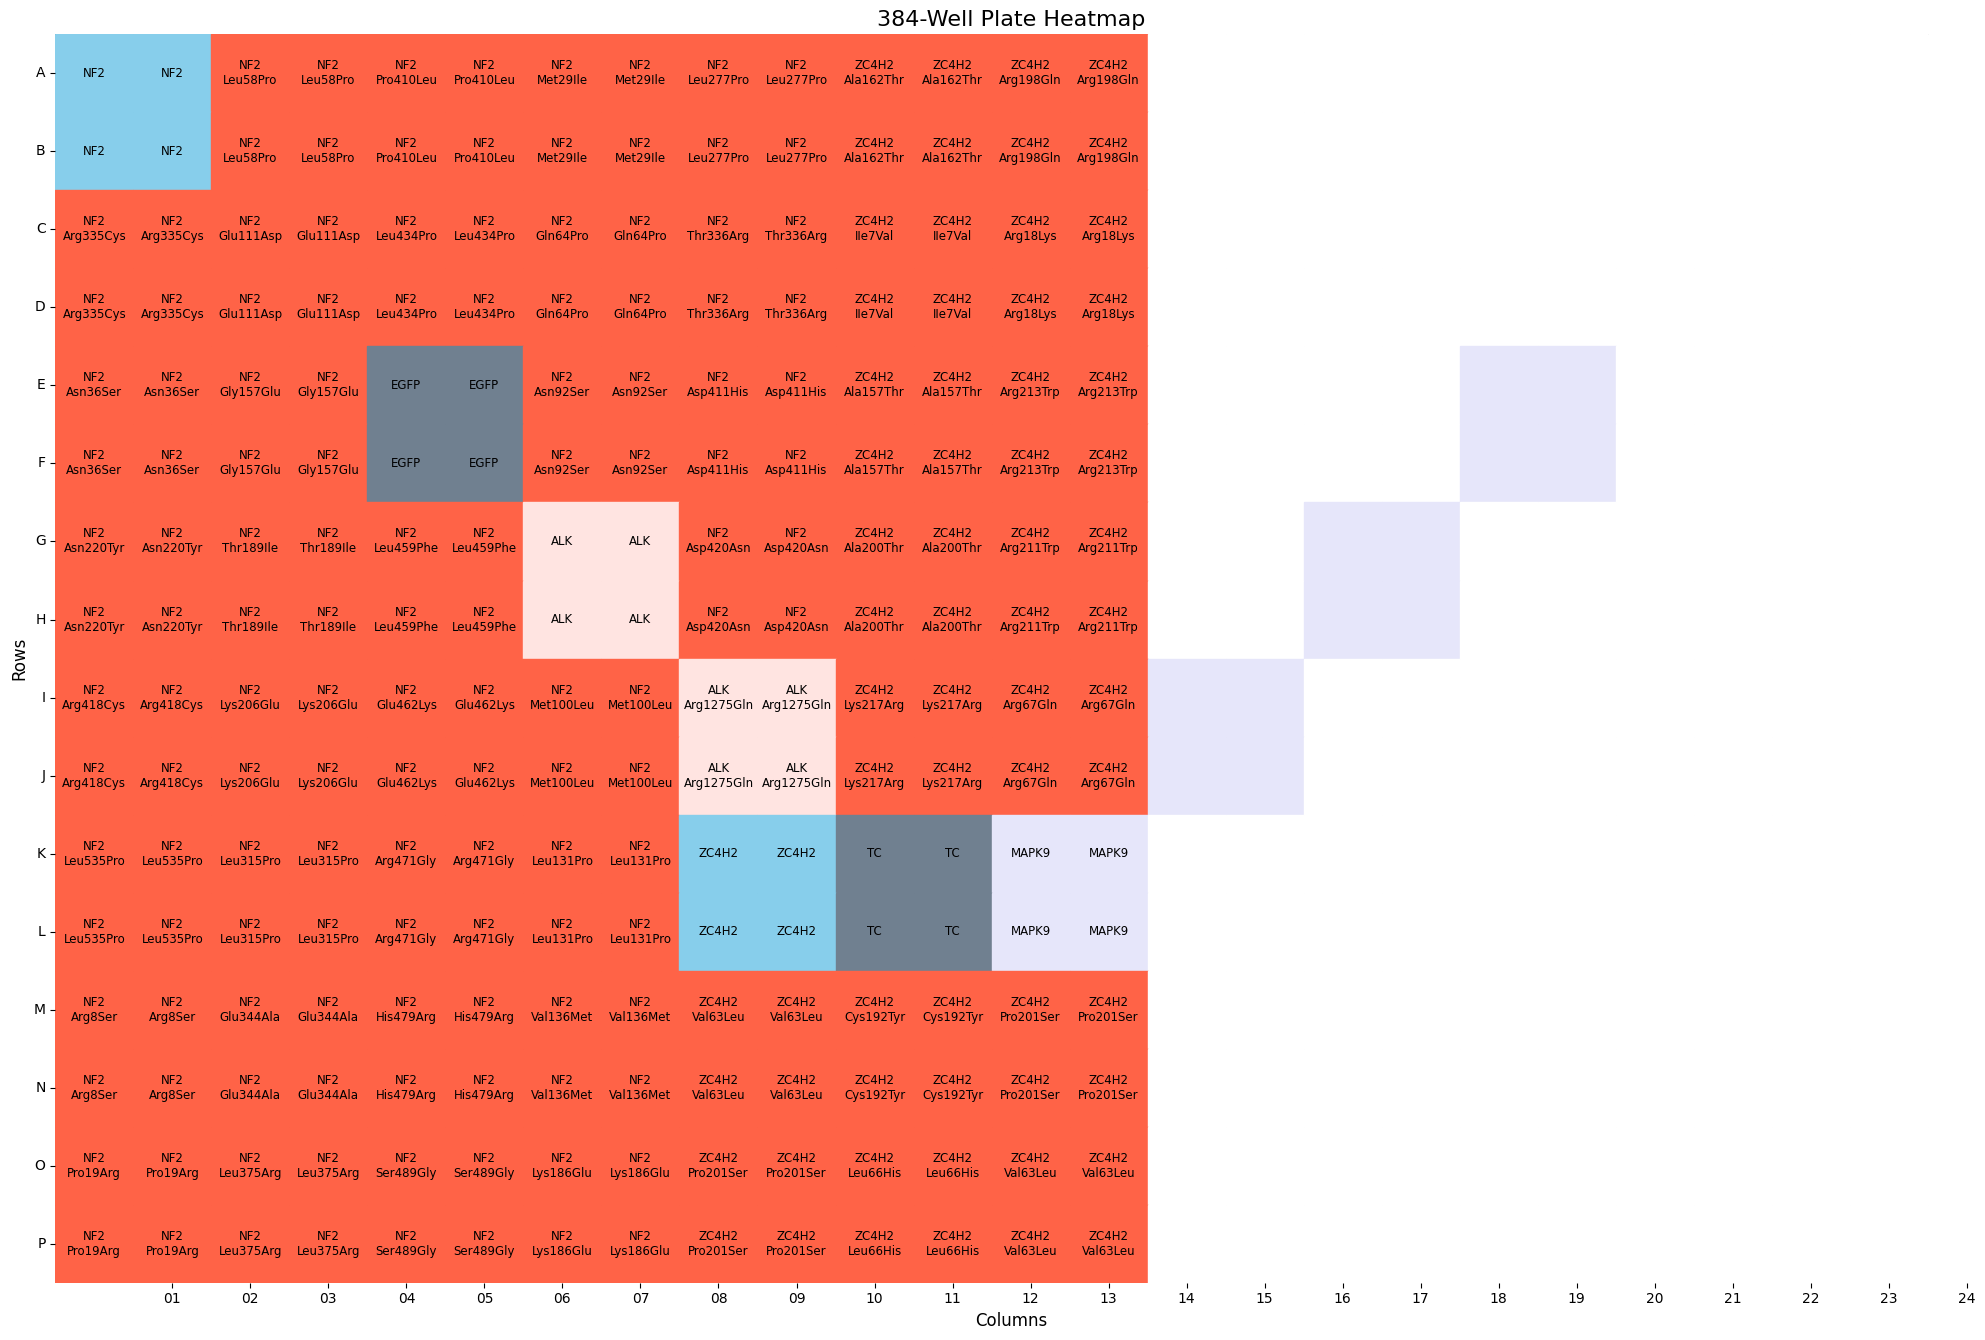

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_well_id,dest_plate,dest_well,dest_well_id,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,ccsb_mutation_id,nt_change,aa_change,technical_replicate,allele_set,imaging_plate,batch1,batch2,vector,control_type,color,label
u64,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""","""P02""","""A01""","""NF2""","""NF2""","""CAVA_CP_P01_Prep2""","""B12""",90,"""CAVA_CP_Array_P02_T1""","""A01""",1,"""A01""","""B9A6R1_P2""","""B10A6R2_P2""","""disease_wt""",3697,null,null,null,1,6,2,9,10,594,"""disease_wt""","""disease_wt""","""NF2"""
1,"""01""","""""","""B""","""01""","""P02""","""B01""","""NF2""","""NF2""","""CAVA_CP_P01_Prep2""","""B12""",90,"""CAVA_CP_Array_P02_T3""","""A01""",1,"""B01""","""B9A6R1_P2""","""B10A6R2_P2""","""disease_wt""",3697,null,null,null,3,6,2,9,10,594,"""disease_wt""","""disease_wt""","""NF2"""
2,"""01""","""""","""C""","""01""","""P02""","""C01""","""NF2""","""NF2_Arg335Cys""","""CAVA_CP_P01_Prep2""","""C12""",91,"""CAVA_CP_Array_P02_T1""","""B01""",2,"""C01""","""B9A6R1_P2""","""B10A6R2_P2""","""allele""",3697,"""CCSBVarC000526""","""1003C>T""","""Arg335Cys""",1,6,2,9,10,594,"""allele""","""allele""","""NF2 Arg335Cys"""
3,"""01""","""""","""D""","""01""","""P02""","""D01""","""NF2""","""NF2_Arg335Cys""","""CAVA_CP_P01_Prep2""","""C12""",91,"""CAVA_CP_Array_P02_T3""","""B01""",2,"""D01""","""B9A6R1_P2""","""B10A6R2_P2""","""allele""",3697,"""CCSBVarC000526""","""1003C>T""","""Arg335Cys""",3,6,2,9,10,594,"""allele""","""allele""","""NF2 Arg335Cys"""
4,"""01""","""""","""E""","""01""","""P02""","""E01""","""NF2""","""NF2_Asn36Ser""","""CAVA_CP_P01""","""F12""",94,"""CAVA_CP_Array_P02_T1""","""C01""",3,"""E01""","""B9A6R1_P2""","""B10A6R2_P2""","""allele""",3697,"""CCSBVarC004111""","""107A>G""","""Asn36Ser""",1,6,2,9,10,594,"""allele""","""allele""","""NF2 Asn36Ser"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11,"""24""","""""","""L""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
12,"""24""","""""","""M""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
13,"""24""","""""","""N""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""


In [37]:
batch9_platemap_confo = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_9_confocal/platemap"
plate_map_id2 = "B9A6R1_P02.txt"
plate_map_2 = pl.read_csv(Path(batch9_platemap_confo) / Path(plate_map_id2), separator='\t', has_header=True)
## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map_2 = plate_map_2.filter(~pl.all_horizontal(pl.all().is_null()))
print(plate_map_2.shape)
plate_map_2 = plate_map_2.with_columns(
    pl.when(pl.col("gene_allele") == "_")  # Condition 1: Keep "_" as is
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.col("node_type").alias("control_type")
)
plot_platemap(plate_map_2)

(376, 24)
Number of unique alleles: ['F9_Asp410His', 'RPS19_Gly127Glu', 'F9_Arg379Gln', 'F9_Arg384Pro', 'PRKACB', 'CTCF_Arg342Gly', 'F9_Cys28Arg', 'FLCN', 'F9_Arg384Leu', 'LMNA_Arg349Leu', 'RAD51D_Arg165Gln', 'G6PD_Glu398Lys', 'BCL10', 'F9_Arg191His', 'CTCF_Tyr407Cys', 'LMNA_Arg331Pro', 'F9_Val374Phe', 'LMNA_Arg133Pro', 'MRE11', 'CTCF_Tyr226Cys', 'ABCD1_Arg389Gly', 'ABCD1_Arg518Gln', 'F9_Asp110Asn', 'F9_Asn306Ser', 'RAD51D', 'F9_His303Tyr', 'SLIRP', 'ABCD1', 'MAPK9', 'CTCF_Arg342Cys', 'F9_Glu27Lys', 'LMNA_Asn456Lys', 'RPS19_Arg101His', 'LMNA_Gly232Glu', 'LMNA_Leu59Arg', 'RPS19_Val15Phe', 'FLCN_Arg239Cys', 'F9_Gly442Arg', 'ABCD1_Arg518Trp', 'CTCF_Glu590Gln', 'F9_Trp453Arg', 'G6PD', 'FANCC', 'F9_Arg294Gln', 'BCL10_Ala5Ser', 'RAD51D_Glu233Gly', 'LMNA_Thr150Pro', 'CTCF_Arg342His', 'LMNA_Ala43Thr', 'F9_Glu73Val', 'CTCF', 'BCL10_Leu8Leu', 'F9_Ile256Thr', 'RHEB', 'F9_Asn166Tyr', 'F9_Ser406Leu', 'CTCF_Arg567Leu', 'FANCC_Asp195Val', 'FANCC_Leu554Pro', 'F9', 'EGFP', 'CTCF_Arg567Trp', 'LMNA_Glu18

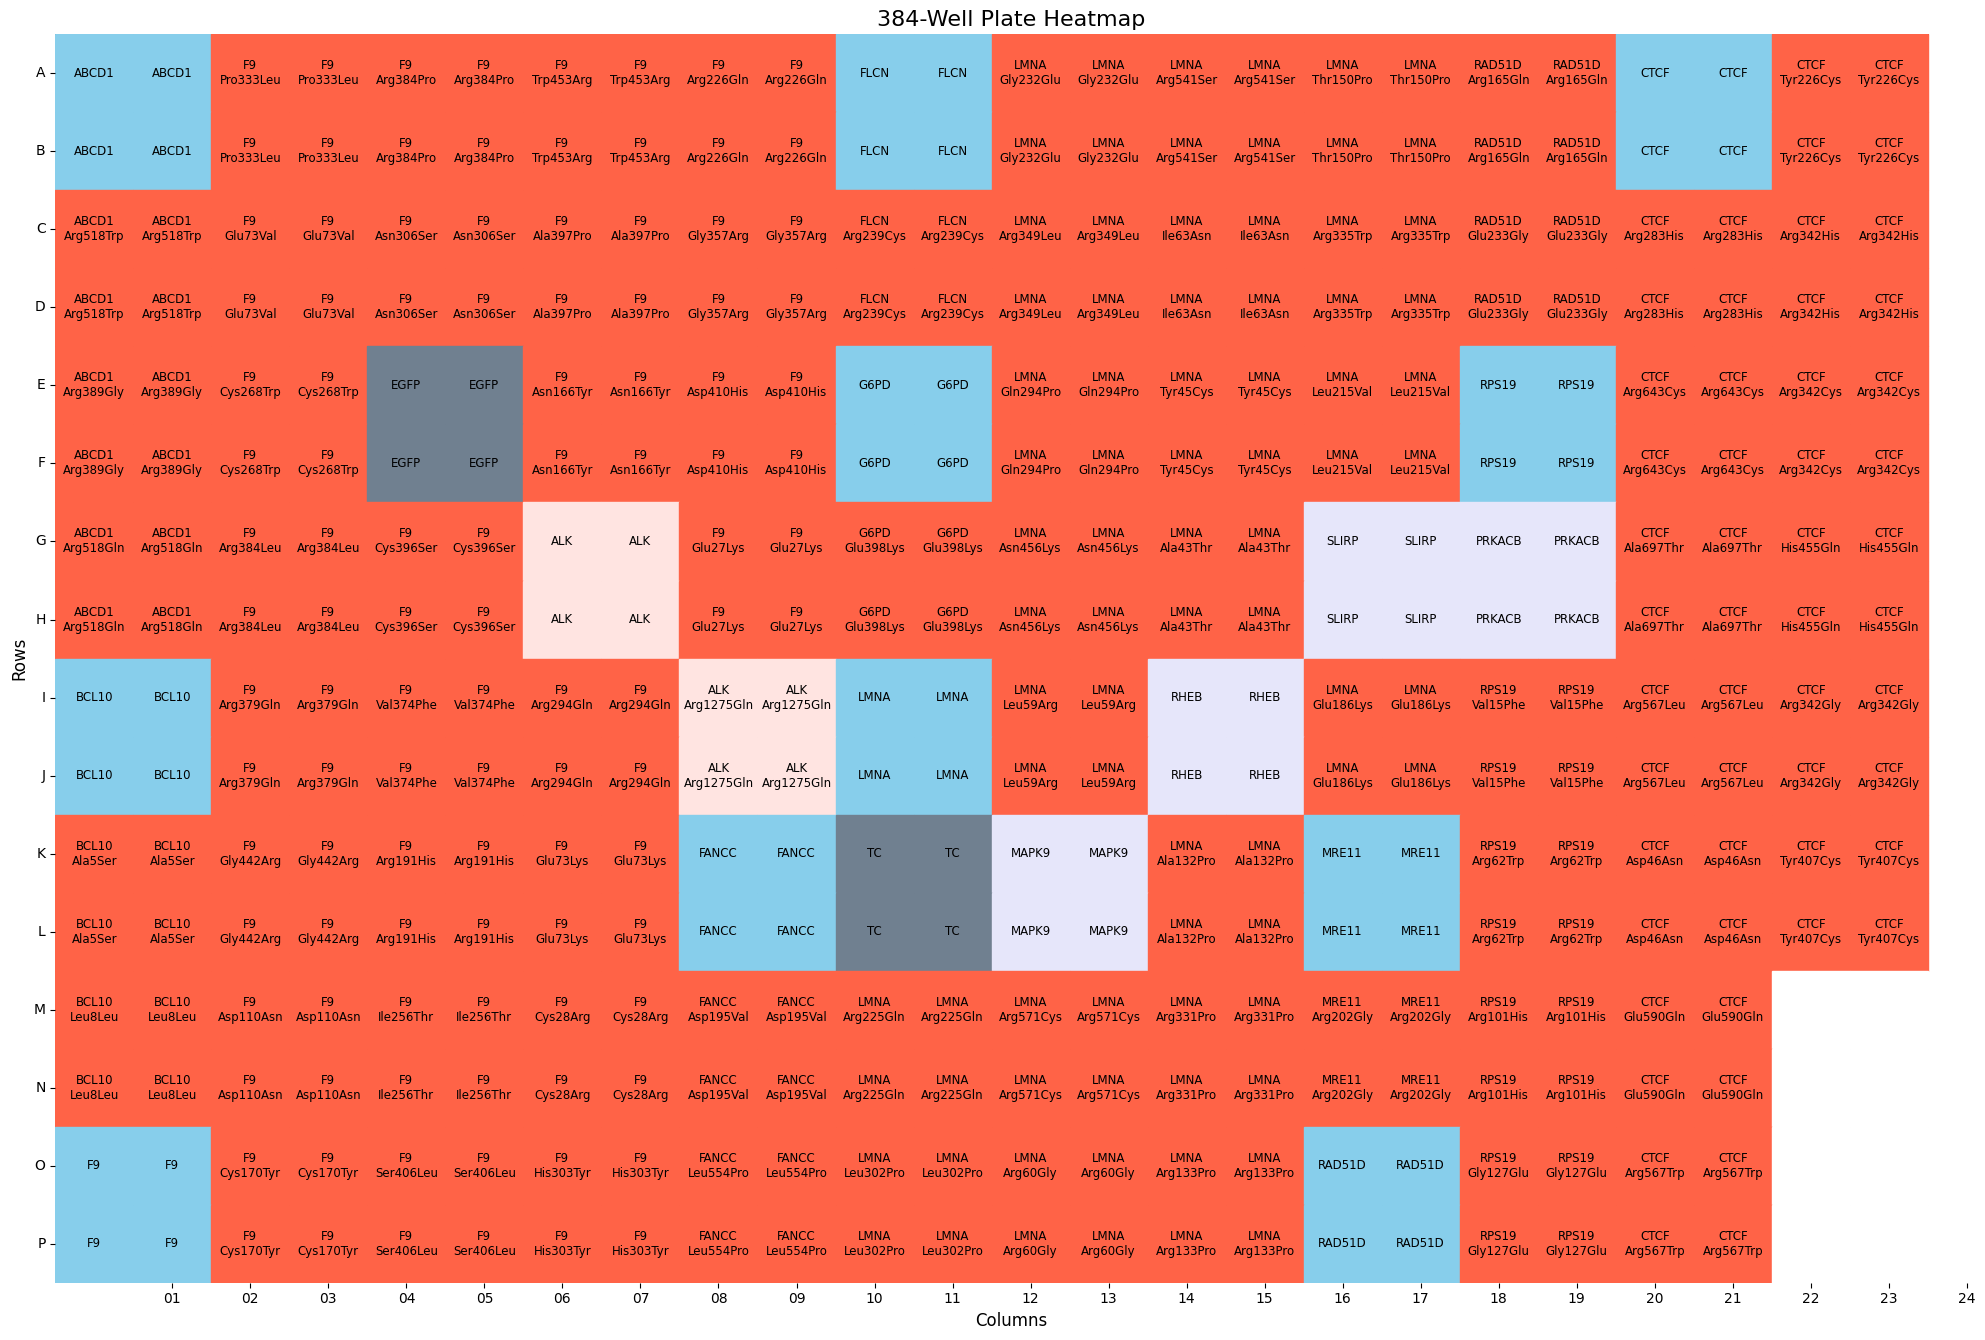

row,col,value,row_label,col_label,plate_map_name,well_position,symbol,gene_allele,source_plate,source_well,source_well_id,dest_plate,dest_well,dest_well_id,imaging_well,imaging_plate_R1,imaging_plate_R2,node_type,orf_id_wt,ccsb_mutation_id,nt_change,aa_change,technical_replicate,allele_set,imaging_plate,batch1,batch2,vector,control_type,color,label
u64,str,str,str,str,str,str,str,str,str,str,i64,str,str,i64,str,str,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""","""P01""","""A01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T1""","""A01""",1,"""A01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,1,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
1,"""01""","""""","""B""","""01""","""P01""","""B01""","""ABCD1""","""ABCD1""","""CAVA_CP_P01_Prep2""","""A01""",1,"""CAVA_CP_Array_P01_T3""","""A01""",1,"""B01""","""B9A6R1_P1""","""B10A6R2_P1""","""disease_wt""",100008637,null,null,null,3,6,1,9,10,594,"""disease_wt""","""disease_wt""","""ABCD1"""
2,"""01""","""""","""C""","""01""","""P01""","""C01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T1""","""B01""",2,"""C01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
3,"""01""","""""","""D""","""01""","""P01""","""D01""","""ABCD1""","""ABCD1_Arg518Trp""","""CAVA_CP_P01_Prep2""","""B01""",2,"""CAVA_CP_Array_P01_T3""","""B01""",2,"""D01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007022""","""1552C>T""","""Arg518Trp""",3,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg518Trp"""
4,"""01""","""""","""E""","""01""","""P01""","""E01""","""ABCD1""","""ABCD1_Arg389Gly""","""CAVA_CP_P01_Prep2""","""C01""",3,"""CAVA_CP_Array_P01_T1""","""C01""",3,"""E01""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",100008637,"""CCSBVarC007023""","""1165C>G""","""Arg389Gly""",1,6,1,9,10,594,"""allele""","""allele""","""ABCD1 Arg389Gly"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
11,"""24""","""""","""L""","""24""","""P01""","""L24""","""CTCF""","""CTCF_Tyr407Cys""","""CAVA_CP_P02""","""H04""",32,"""CAVA_CP_Array_P01_T4""","""F12""",94,"""L24""","""B9A6R1_P1""","""B10A6R2_P1""","""allele""",6173,"""CCSBVarC010870""","""1220A>G""","""Tyr407Cys""",4,6,1,9,10,594,"""allele""","""allele""","""CTCF Tyr407Cys"""
12,"""24""","""""","""M""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""
13,"""24""","""""","""N""","""24""",null,null,"""""","""""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""""",""""""


In [42]:
batch9_platemap_wf = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_9_widefield/platemap"
plate_map_id2 = "B9A6R1_P01_widefield.txt"
plate_map_2 = pl.read_csv(Path(batch9_platemap_wf) / Path(plate_map_id2), separator='\t', has_header=True)
## Drop a row only if all values are null: 
## (DO NOT use drop_nulls() directly here as it drops all rows with a null in it)
plate_map_2 = plate_map_2.filter(~pl.all_horizontal(pl.all().is_null()))
print(plate_map_2.shape)
column_name = "gene_allele"
plate_map_2 = plate_map_2.with_columns(
    pl.when(pl.col("gene_allele") == "_")  # Condition 1: Keep "_" as is
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.ends_with("_") & (pl.col("gene_allele") != "_"))  # Condition 2: Remove trailing "_"
        .then(pl.col("gene_allele").str.replace(r"_$", ""))  # Remove trailing "_"
        .otherwise(pl.col("gene_allele"))  # Keep other values unchanged
        .alias("gene_allele"),  # Replace the original column,
    pl.when(pl.col("gene_allele") == "_")
        .then(pl.col("gene_allele"))
        .when(pl.col("gene_allele").str.contains("_"))
        .then(pl.col("gene_allele").str.extract(r"^(.*?)_", 1))
        .otherwise(pl.col("gene_allele"))
        .alias("symbol"),
    pl.col("node_type").alias("control_type")
    # pl.when(pl.col("gene_allele") == "_")
    #     .then(pl.lit("control"))
    #     .when(pl.col("gene_allele").str.contains("_"))
    #     .then(pl.lit("allele"))
    #     .otherwise(pl.lit("disease_wt"))
    #     .alias("control_type"),
)
# plate_map
# print(plate_map.select(pl.col(column_name).unique()))
# print(plate_map.select(pl.col("gene_allele").unique()))
# # print(plate_map.select(pl.col("symbol").unique()))
plot_platemap(plate_map_2)

In [193]:
# batch10_platemap_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/6.downstream_analysis_snakemake/inputs/metadata/platemaps/2024_10_28_Batch_10_widefield/platemap"
# plate_map_id = "B10A6R2_P01_widefield.txt"
# plate_map = pl.read_csv(Path(batch10_platemap_dir) / Path(plate_map_id), separator='\t', has_header=True)
# plate_map = plate_map.drop_nulls()
# plate_map = plate_map.with_columns(pl.col("node_type").alias("control_type"))
# plot_platemap(plate_map)

## Batch 7/8

shape: (92, 1)
┌────────┐
│ symbol │
│ ---    │
│ str    │
╞════════╡
│ CTRC   │
│ BTC    │
│ EZH2   │
│ RHEB   │
│ ACY1   │
│ …      │
│ COL2A1 │
│ ANKRD1 │
│ ADIPOQ │
│ CREB1  │
│ AGXT   │
└────────┘


plate_map_name,well_position,control_type,symbol,gene_allele,…,c96,r96,r384,c384,r384_letter
str,str,str,str,str,…,i64,i64,i64,i64,str
"""B7A1R1_P1""","""A01""","""disease_wt""","""ACSF3""","""ACSF3""",…,1,1,1,1,"""A"""
"""B7A1R1_P1""","""C01""","""allele""","""ACSF3""","""ACSF3_Ala197Thr""",…,1,2,3,1,"""C"""
"""B7A1R1_P1""","""E01""","""allele""","""ACSF3""","""ACSF3_Thr358Ile""",…,1,3,5,1,"""E"""
"""B7A1R1_P1""","""G01""","""allele""","""ACSF3""","""ACSF3_Met198Arg""",…,1,4,7,1,"""G"""
"""B7A1R1_P1""","""I01""","""allele""","""ACSF3""","""ACSF3_Glu359Lys""",…,1,5,9,1,"""I"""
"""B7A1R1_P1""","""K01""","""allele""","""ACSF3""","""ACSF3_Ile200Met""",…,1,6,11,1,"""K"""
"""B7A1R1_P1""","""M01""","""allele""","""ACSF3""","""ACSF3_Ser431Tyr""",…,1,7,13,1,"""M"""
"""B7A1R1_P1""","""O01""","""allele""","""ACSF3""","""ACSF3_Gly225Arg""",…,1,8,15,1,"""O"""
"""B7A1R1_P1""","""A03""","""allele""","""ACSF3""","""ACSF3_Asp457Asn""",…,2,1,1,3,"""A"""


Number of unique alleles: ['AGXT_Met49Leu', 'ALAS2_Asp122Asn', 'ACSF3_Ile200Met', 'DES_Thr453Ile', 'DES_Met349Ile', 'AGXT_Arg301Cys', 'DES_Ala135Val', 'ADIPOQ', 'AGXT', 'AIPL1_Thr114Ile', 'AQP1', 'ACSF3', 'COMP_Asp319Val', 'AGXT_Ala186Val', 'CORO1A', 'ACSF3_Ser431Tyr', 'CYP21A2', 'AGXT_Ala85Asp', 'ALAS2_Ala135Thr', 'AGXT_Asp341Glu', 'ALAS2', 'COMP_Asp408Asn', 'DES_Ser46Tyr', 'BRIP1', 'EFHC1_Ile174Val', 'ALOX5', 'CTRC_Glu225Ala', 'AGXT_Arg197Gln', 'AGXT_Ala248Val', 'AIPL1_Met79Thr', 'CRYAB_Gly154Ser', 'AGXT_Asp129His', 'APOA1_Ala199Pro', 'EMD_Asp72Val', 'CBR3', 'ACSF3_Gly225Arg', 'DCX_Lys174Glu', 'AGXT_Ile202Asn', 'DES_Val56Leu', 'APOA1_Trp74Arg', 'AGXT_Leu298Pro', 'AGXT_Met195Leu', 'COMP_Thr585Met', 'DMC1', 'DCX_Arg89Gly', 'BLMH_Ile443Val', 'DES_Tyr331Asn', 'AMPD2', 'ACSF3_Arg558Trp', 'FADD_Cys105Trp', 'EMD_Met1Val', 'EIF2B4', 'ALAS2_Phe128Leu', 'DES_Pro433Thr', 'ACSF3_Ala197Thr', 'AGXT_Gly161Arg', 'DES_Gln389Pro', 'ACSF3_Arg471Trp', 'AGXT_Ser221Pro', 'EIF2B4_Ala228Val', 'ANKRD1', 'CLD

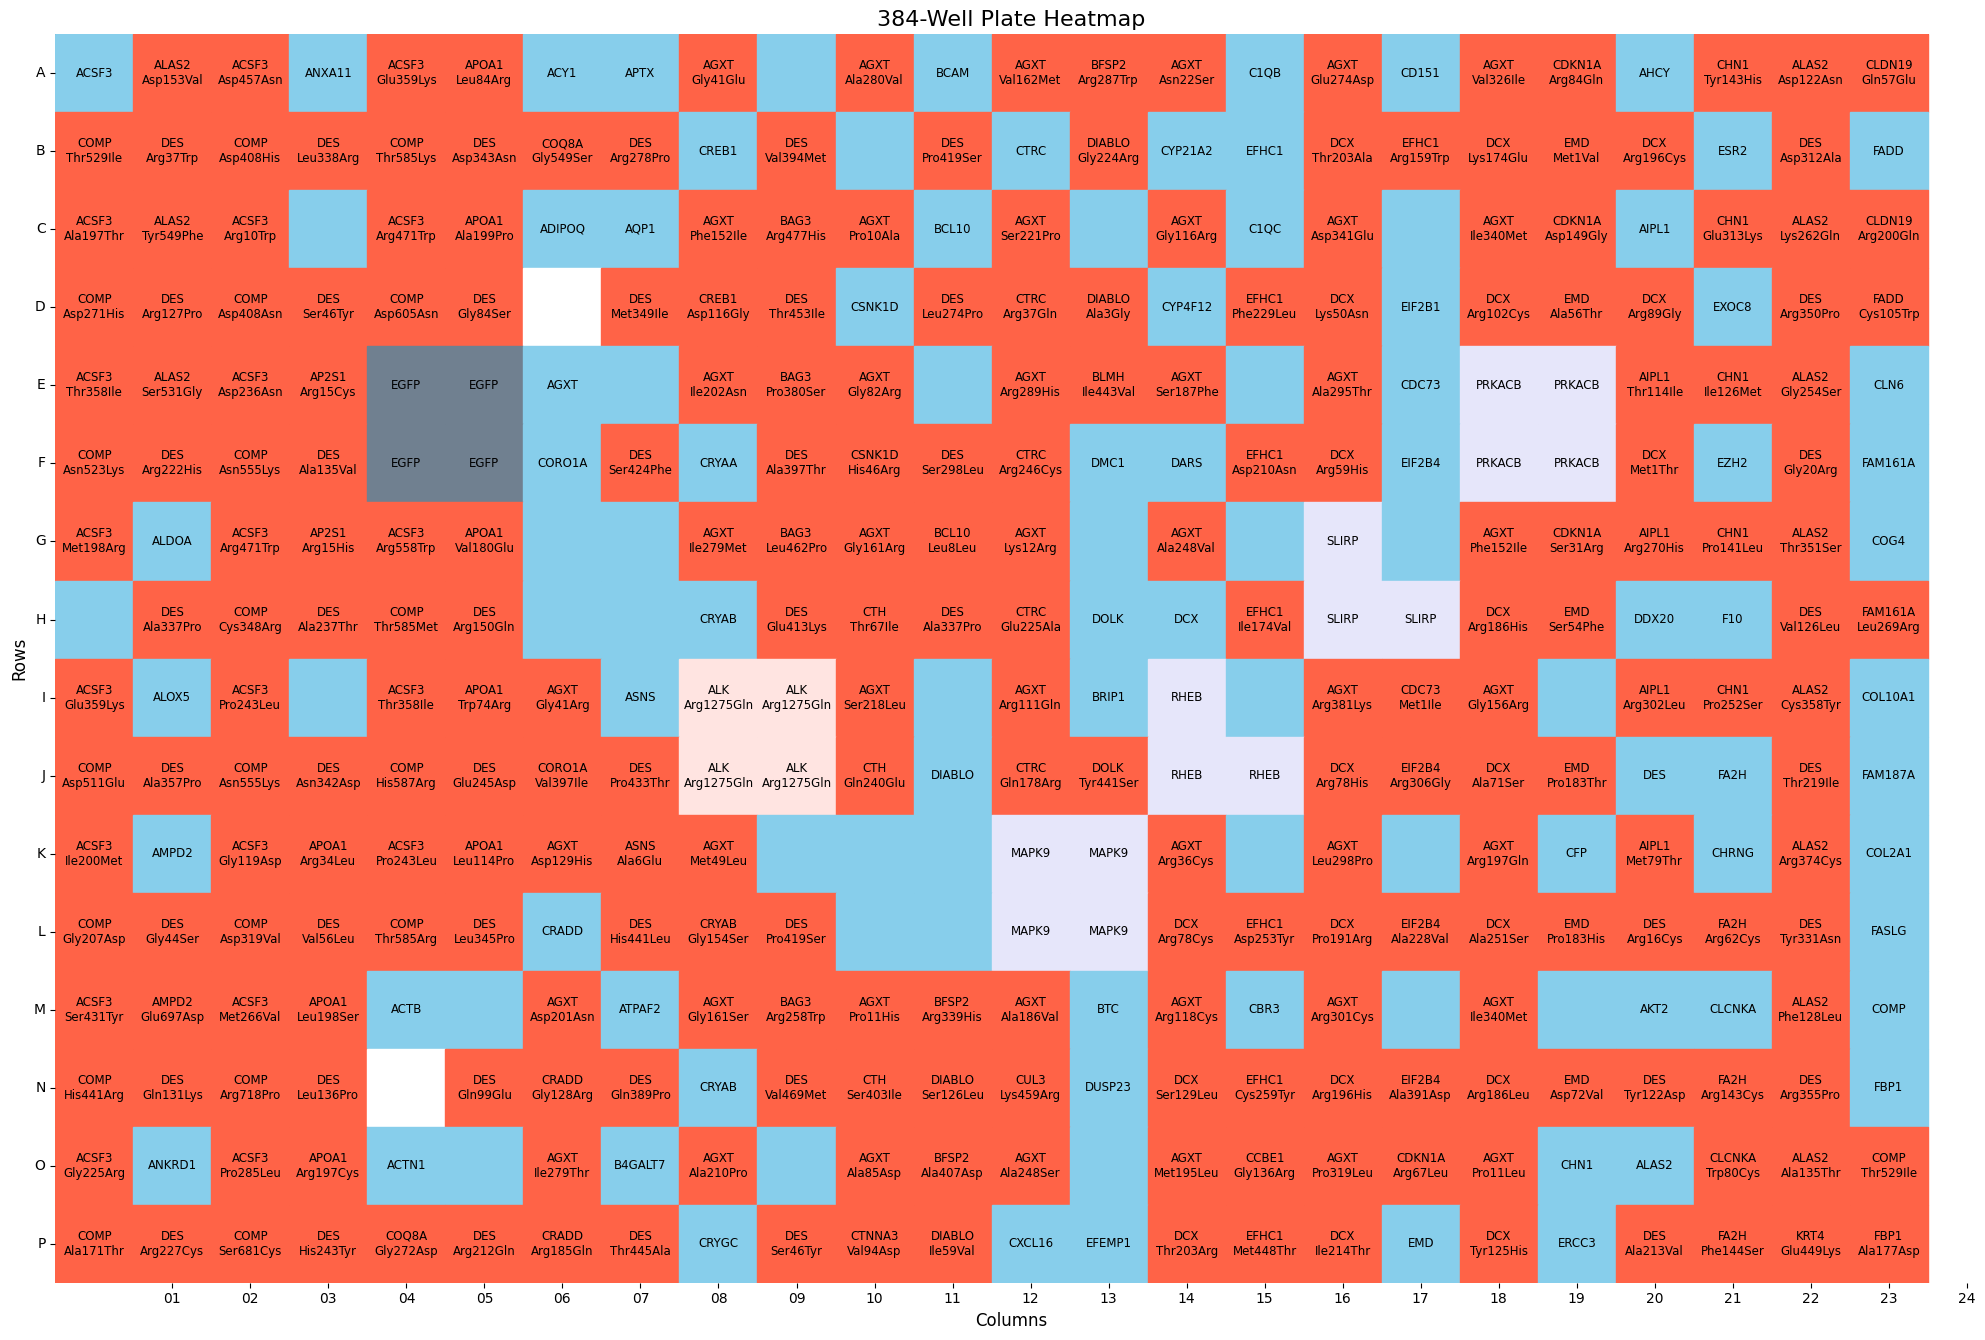

row,col,value,row_label,col_label,…,r384,c384,r384_letter,color,label
u64,str,str,str,str,…,i64,i64,str,str,str
0,"""01""","""""","""A""","""01""",…,1,1,"""A""","""disease_wt""","""ACSF3"""
1,"""01""","""""","""B""","""01""",…,2,1,"""B""","""allele""","""COMP Thr529Ile"""
2,"""01""","""""","""C""","""01""",…,3,1,"""C""","""allele""","""ACSF3 Ala197Thr"""
3,"""01""","""""","""D""","""01""",…,4,1,"""D""","""allele""","""COMP Asp271His"""
4,"""01""","""""","""E""","""01""",…,5,1,"""E""","""allele""","""ACSF3 Thr358Ile"""
5,"""01""","""""","""F""","""01""",…,6,1,"""F""","""allele""","""COMP Asn523Lys"""
6,"""01""","""""","""G""","""01""",…,7,1,"""G""","""allele""","""ACSF3 Met198Arg"""
7,"""01""","""""","""H""","""01""",…,8,1,"""H""","""disease_wt""",""""""
8,"""01""","""""","""I""","""01""",…,9,1,"""I""","""allele""","""ACSF3 Glu359Lys"""


In [45]:
batch7_platemap_dir = "/home/shenrunx/igvf/varchamp/2021_09_01_VarChAMP/7.analysis_runxi/output/meta_correct_batch78/2024_01_23_Batch_7"
plate7_map_id = "B7A1R1_P1.txt"
plate7_map = pl.read_csv(Path(batch7_platemap_dir) / Path(plate7_map_id), separator='\t', has_header=True)
print(plate7_map.select(pl.col("symbol").unique()))

pl.Config.set_tbl_rows(200)  # Show all rows
pl.Config.set_tbl_cols(10)  # Show all columns
display(plate7_map)
# print("Number of unique alleles:", plate7_map.select(pl.col("gene_allele").unique()))
plate7_map.head() #  = plate_map.drop_nulls()
# print(plate7_map.filter(pl.col("symbol").is_in(TC+NC+PC+cNC+cPC) | pl.col("gene_allele").is_in(TC+NC+PC+cNC+cPC)))
# print(plate7_map.filter(pl.col("symbol").is_in(TC+NC+PC+cNC+cPC)))
plot_platemap(plate7_map)

In [4]:
# def check_batch_pms(batch_dir):
#     platemap_set = sorted(set([platemap_id.split('_T')[0] for platemap_id in os.listdir(batch_dir)]))
#     print("Platemaps available for batch:", platemap_set)
#     for platemap_id in platemap_set:
#         pm_ref_df = pl.read_csv(Path(batch_dir) / Path(platemap_id+"_T1.txt"), separator='\t', has_header=True)
#         columns_to_include = pm_ref_df.columns[1:]
#         for pm_file in [pm for pm in os.listdir(batch_dir) if platemap_id in pm and "T1" not in pm]:
#             pm_df = pl.read_csv(Path(batch_dir) / Path(pm_file), separator='\t', has_header=True)
#             df1_selected = pm_ref_df.select(columns_to_include)
#             df2_selected = pm_df.select(columns_to_include)
#             assert df1_selected.equals(df2_selected)
#             print(f"{pm_file} is equal to ref. {platemap_id}_T1.txt")